# SynthaDrive, phase 1 : 3D Gaussian Splatting sur nuScenes (partie 3 sur 3)

Cette dernière partie de la phase 1 contient trois expériences sur la scène 0061 :

- l'expérience 4 compare une initialisation des gaussiennes par le lidar (modèle C) à l'initialisation aléatoire ;
- l'expérience 6 compare trois nuages lidar pour cette initialisation (L1, L2 et L3) ;
- l'expérience 7 entraîne le modèle sur les trois caméras avant. Ses variantes 7b et 7c corrigent l'exposition des caméras latérales et allongent l'entraînement. Je décale ensuite la caméra sur le côté pour juger les nouvelles vues.

Le notebook se termine par le bilan de la phase 1, qui explique le passage à OmniRe.

Les entraînements ont été faits lors de sessions précédentes et leurs résultats sont restaurés depuis mes datasets Kaggle. Cette partie réutilise aussi le découpage et les modèles de l'expérience 5 (partie 2).

---
# En-tête : installation, données et fonctions communes

Cet en-tête est le même que celui de la partie 1.

In [1]:
# Vérifie si le cache de compilation de gsplat a été conservé d'une session à l'autre
import os
if os.path.isdir('/kaggle/working/torch_extensions'):
    print('cache gsplat présent : pas de recompilation')
else:
    print('pas de cache : gsplat va compiler (~17 min)')

pas de cache : gsplat va compiler (~17 min)


## 1. Prérequis

Je vérifie qu'Internet et le GPU sont bien activés.

In [2]:
import socket, torch, torchvision

try:
    socket.gethostbyname('pypi.org')
    print('Internet : OK')
except Exception as e:
    raise RuntimeError('Internet désactivé → Settings > Internet > On') from e

if not torch.cuda.is_available():
    raise RuntimeError('Pas de GPU → Settings > Accelerator > GPU T4 x2')

print('GPU         :', torch.cuda.get_device_name(0))
print('PyTorch     :', torch.__version__)
print('torchvision :', torchvision.__version__)
print('CUDA        :', torch.version.cuda)


Internet : OK
GPU         : Tesla T4
PyTorch     : 2.10.0+cu128
torchvision : 0.25.0+cu128
CUDA        : 12.8


In [3]:
# gsplat compile ses noyaux CUDA à la volée, il lui faut nvcc
!which nvcc && nvcc --version | tail -2


/usr/local/cuda/bin/nvcc
Cuda compilation tools, release 12.8, V12.8.93
Build cuda_12.8.r12.8/compiler.35583870_0


## 2. Installation

J'installe explicitement les 45 dépendances de nerfstudio 1.1.5 (`tyro`, `viser`, `gsplat`, `pyquaternion`, etc.), sans `nuscenes-devkit`, puis nerfstudio lui-même avec `--no-deps` pour que pip ne le réintroduise pas.

Un fichier de contraintes fige les versions de `torch`, `torchvision` et `numpy` déjà installées par Kaggle. Sans lui, pip les remplaçait et PyTorch ne trouvait plus `libcuda.so`.

L'installation prend une dizaine de minutes.

In [4]:
import torch, torchvision, numpy, pathlib

# Fichier de contraintes : pip ne doit pas remplacer les versions installées par Kaggle

pathlib.Path('/kaggle/working/constraints.txt').write_text(
    f"torch=={torch.__version__.split('+')[0]}\n"
    f"torchvision=={torchvision.__version__.split('+')[0]}\n"
    f"numpy=={numpy.__version__}\n"
)

# Liste tirée des métadonnées officielles de nerfstudio 1.1.5, sans nuscenes-devkit
deps = """appdirs>=1.4
av>=9.2.0
comet-ml>=3.33.8
cryptography>=38
tyro>=0.6.6
gdown>=4.6.0
ninja>=1.10
h5py>=2.9.0
imageio>=2.21.1
ipywidgets>=7.6
jaxtyping>=0.2.15
jupyterlab>=3.3.4
matplotlib>=3.6.0
mediapy>=1.1.0
msgpack>=1.0.4
msgpack-numpy>=0.4.8
nerfacc==0.5.2
open3d>=0.16.0
opencv-python-headless==4.10.0.84
Pillow>=10.3.0
plotly>=5.7.0
protobuf!=3.20.0,<=3.20.3
pyngrok>=5.1.0
python-socketio>=5.7.1
pyquaternion>=0.9.9
requests
rich>=12.5.1
scikit-image>=0.19.3
splines==0.3.0
tensorboard>=2.13.0
torchmetrics[image]>=1.0.1
typing-extensions>=4.4.0
viser==0.2.7
wandb>=0.13.3
xatlas
trimesh>=3.20.2
timm==0.6.7
gsplat==1.4.0
pytorch-msssim
pathos
packaging
fpsample
tensorly
rawpy>=0.18.1
pymeshlab>=2022.2.post2
"""
pathlib.Path('/kaggle/working/requirements.txt').write_text(deps)
print(len([l for l in deps.splitlines() if l.strip()]), 'dépendances à installer')


45 dépendances à installer


In [5]:
!pip install -r /kaggle/working/requirements.txt -c /kaggle/working/constraints.txt


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.4/40.4 kB 1.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 1.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 kB 1.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
INFO: pip is looking at multiple versions of wandb to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of wandb to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.5/55.5 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 13.2 MB/s eta 0:00:0000:0100:01
   ━

In [6]:
# Relier les checkpoints sauvegardés dans le dataset aux dossiers de travail
from pathlib import Path
import os

SAVED = Path('/kaggle/input/datasets/adbiashouessou/syntha-drive-resultats/outputs')
WORK  = Path('/kaggle/working/outputs')
print('dataset attaché :', SAVED.exists())

for src in SAVED.glob('*/splatfacto/*/nerfstudio_models'):
    run_rel = src.parent.relative_to(SAVED)          # par exemple exp7_3cams/splatfacto/2026-10-21_160447
    dst_run = WORK / run_rel
    dst = dst_run / 'nerfstudio_models'

    # Un vrai dossier de checkpoints déjà présent : on n'y touche pas
    if dst.is_dir() and any(dst.glob('*.ckpt')):
        continue

    # Raccourci cassé, fichier à la place du dossier, ou dossier vide : on l'enlève
    if os.path.islink(dst) or dst.is_file():
        os.remove(dst)
    elif dst.is_dir():
        dst.rmdir()                                    # seulement s'il est vide

    dst_run.mkdir(parents=True, exist_ok=True)
    if not (dst_run / 'config.yml').exists():          # config du run, si elle manque aussi
        os.symlink(src.parent / 'config.yml', dst_run / 'config.yml')
        os.symlink(src.parent / 'dataparser_transforms.json', dst_run / 'dataparser_transforms.json')
    os.symlink(src, dst)
    print('relié :', run_rel)

!ls /kaggle/working/outputs/exp7_3cams/splatfacto/*/nerfstudio_models/

dataset attaché : True
relié : exp6_L3/splatfacto/2026-10-21_104521
relié : exp7_3cams/splatfacto/2026-10-21_160447
relié : nerf_data/splatfacto/2026-09-25_213207
relié : nerf_data_A_prime/splatfacto/2026-10-14_105020
relié : nerf_data_B/splatfacto/2026-10-14_110945
relié : nerf_data_B_30k/splatfacto/2026-10-16_115053
relié : nerf_data_tvt/splatfacto/2026-10-20_202148
relié : nerf_data_tvt_lidar/splatfacto/2026-10-20_220400
step-000002500.ckpt  step-000010000.ckpt  step-000017500.ckpt
step-000005000.ckpt  step-000012500.ckpt  step-000017999.ckpt
step-000007500.ckpt  step-000015000.ckpt


In [7]:
!pip install nerfstudio==1.1.5 --no-deps


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 580.8/580.8 kB 10.2 MB/s eta 0:00:00a 0:00:01


In [8]:
# Je récupère la wheel de gsplat déjà compilée dans mon dataset Kaggle, ce qui évite environ 17 min de compilation
import os, glob, shutil, zipfile
SRC = next(iter(glob.glob('/kaggle/input/**/syntha-drive-resultats', recursive=True)),
           '/kaggle/input/datasets/adbiashouessou/syntha-drive-resultats')   # chemin trouvé automatiquement
if not glob.glob('/kaggle/working/wheels/gsplat-*.whl') and os.path.isdir(SRC):
    os.makedirs('/kaggle/working/wheels', exist_ok=True)
    whl = glob.glob(f'{SRC}/**/gsplat-*.whl', recursive=True)
    if whl:                                            # dataset décompressé par Kaggle
        shutil.copy(whl[0], '/kaggle/working/wheels/')
    else:                                              # dataset resté en zip
        for z in glob.glob(f'{SRC}/**/*.zip', recursive=True):
            with zipfile.ZipFile(z) as zf:
                for m in zf.namelist():
                    if m.startswith(('wheels/', './wheels/')) and m.endswith('.whl'):
                        zf.extract(m, '/kaggle/working')
print('wheel gsplat :', glob.glob('/kaggle/working/wheels/gsplat-*.whl') or 'absente (compilation au prochain pas)')


wheel gsplat : ['/kaggle/working/wheels/gsplat-1.4.0-cp312-cp312-linux_x86_64.whl']


In [9]:
# Sans wheel, je compile gsplat une seule fois (15 à 20 min). Ensuite, la réinstallation prend quelques secondes.
import glob
whl = glob.glob('/kaggle/working/wheels/gsplat-*.whl')
if not whl:
    print('Aucune wheel : compilation unique de gsplat...')
    !TORCH_CUDA_ARCH_LIST="7.5" MAX_JOBS=2 pip wheel "git+https://github.com/nerfstudio-project/gsplat.git@v1.4.0" --no-deps --no-build-isolation -w /kaggle/working/wheels
    whl = glob.glob('/kaggle/working/wheels/gsplat-*.whl')
!pip install --no-deps --force-reinstall -q {whl[0]}
!ls -lh /kaggle/working/wheels

total 8.3M
-rw-r--r-- 1 root root 8.3M Oct 30 21:36 gsplat-1.4.0-cp312-cp312-linux_x86_64.whl


Les avertissements `protobuf ... is incompatible` qui concernent `google-cloud-*`, `shap` ou `grain` n'ont pas d'effet ici. Ce sont des paquets préinstallés par Kaggle que je n'utilise pas, et c'est la contrainte `protobuf<=3.20.3` de nerfstudio qui les gêne.

In [ ]:
# Contrôle : numpy doit toujours être en version 2 et PyTorch doit toujours voir le GPU
import torch, numpy, nerfstudio, tyro, gsplat, viser
from pyquaternion import Quaternion
from importlib.metadata import version

print('torch      :', torch.__version__, '| CUDA :', torch.cuda.is_available())
print('numpy      :', numpy.__version__)
print('nerfstudio :', version('nerfstudio'))
print('tyro, gsplat, viser, pyquaternion : OK')

assert torch.cuda.is_available(), 'PyTorch a perdu le GPU'
assert numpy.__version__.startswith('2'), 'numpy a été rétrogradé — nuscenes-devkit a dû être tiré'
print('\nInstallation cohérente')

torch      : 2.10.0+cu128 | CUDA : True
numpy      : 2.0.2
nerfstudio : 1.1.5
tyro, gsplat, viser, pyquaternion : OK

Installation cohérente ✅


## 3. Compilation de gsplat

Je la lance dans une cellule à part parce qu'elle prend plusieurs minutes. Si elle échoue, autant que ce soit ici plutôt qu'au début de l'entraînement.

Deux réglages comptent :

- `MAX_JOBS=2`. La wheel de gsplat ne contient aucun binaire précompilé (`py3-none-any`) : ses 1693 sources CUDA sont compilées à la première utilisation, avec 10 compilations `nvcc` en parallèle par défaut (`MAX_JOBS=10` dans son code). Sur Kaggle, ça sature la RAM, le système tue un processus et ninja s'arrête sur `build stopped: subcommand failed`. Si l'erreur revient, on peut descendre à `MAX_JOBS=1`.
- `TORCH_EXTENSIONS_DIR` dans `/kaggle/working`. Le cache par défaut (`~/.cache`) disparaît au redémarrage, alors que celui-ci est conservé.

Ces deux variables doivent être définies avant le premier `import gsplat`.

In [11]:
import os

os.environ['MAX_JOBS'] = '2'
os.environ['TORCH_EXTENSIONS_DIR'] = '/kaggle/working/torch_extensions'
os.makedirs(os.environ['TORCH_EXTENSIONS_DIR'], exist_ok=True)

print('MAX_JOBS             :', os.environ['MAX_JOBS'])
print('TORCH_EXTENSIONS_DIR :', os.environ['TORCH_EXTENSIONS_DIR'])


MAX_JOBS             : 2
TORCH_EXTENSIONS_DIR : /kaggle/working/torch_extensions


In [12]:
# Lance la compilation CUDA : longue la première fois, instantanée ensuite grâce au cache
import time
t0 = time.time()
from gsplat.cuda._backend import _C
print(f'gsplat compilé et chargé en {time.time() - t0:.0f}s')


gsplat compilé et chargé en 0s


In [13]:
import torch
print(torch.__version__, torch.version.cuda)   # par exemple 2.4.0  12.4

2.10.0+cu128 12.8


In [14]:
# Test de rendu sur le GPU : si ce rendu passe, l'entraînement passera aussi
import torch
from gsplat import rasterization

N = 100
g = torch.Generator(device='cuda').manual_seed(0)
means     = torch.randn(N, 3, device='cuda', generator=g)
quats     = torch.randn(N, 4, device='cuda', generator=g)
scales    = torch.rand(N, 3, device='cuda', generator=g) * 0.1
opacities = torch.rand(N, device='cuda', generator=g)
colors    = torch.rand(N, 3, device='cuda', generator=g)
viewmats  = torch.eye(4, device='cuda')[None]
Ks = torch.tensor([[[300., 0., 150.], [0., 300., 100.], [0., 0., 1.]]], device='cuda')

out, alpha, meta = rasterization(means, quats, scales, opacities, colors,
                                 viewmats, Ks, width=300, height=200)
print('Rendu test OK — shape :', tuple(out.shape))


Rendu test OK — shape : (1, 200, 300, 3)


## 4. Données nuScenes mini

Le téléchargement fait environ 4 Go. Il est sauté si les données sont déjà là.

On peut aussi s'en passer : nuScenes mini existe comme dataset public sur Kaggle. Il suffit de l'ajouter avec *Add Input*, de faire pointer `DATAROOT` vers son dossier dans `/kaggle/input/` et de sauter la cellule de téléchargement.

In [15]:
DATAROOT   = '/kaggle/working/data/sets/nuscenes'
OUTPUT_DIR = '/kaggle/working/nerf_data'
VERSION    = 'v1.0-mini'

In [16]:
%%bash
set -e
DEST=/kaggle/working/data/sets/nuscenes
mkdir -p $DEST

if [ ! -d "$DEST/v1.0-mini" ]; then
    echo 'Téléchargement de nuScenes v1.0-mini (~4 Go)...'
    wget --progress=dot:giga https://www.nuscenes.org/data/v1.0-mini.tgz -O /kaggle/working/v1.0-mini.tgz
    tar -xzf /kaggle/working/v1.0-mini.tgz -C $DEST
    rm -f /kaggle/working/v1.0-mini.tgz
    echo 'Terminé'
else
    echo 'Dataset déjà présent'
fi
du -sh $DEST


Dataset déjà présent
5.1G	/kaggle/working/data/sets/nuscenes


## Fonctions communes

Je reprends ici les fonctions de la partie 1 (section 5) qui lisent les tables nuScenes et calculent les poses.

In [17]:
# Fonctions reprises de la partie 1, section 5
import os, json
import numpy as np

def load_tables(dataroot, version):
    """Charge les six tables nuScenes utiles (scene, sample, sample_data, sensor,
    calibrated_sensor, ego_pose). Renvoie un dictionnaire {nom: liste d'enregistrements}."""
    p = os.path.join(dataroot, version)
    names = ['scene', 'sample', 'sample_data', 'sensor', 'calibrated_sensor', 'ego_pose']
    return {n: json.load(open(os.path.join(p, f'{n}.json'))) for n in names}

def quat_to_rotmat(q):
    """Convertit un quaternion nuScenes [w, x, y, z] en matrice de rotation 3x3."""
    w, x, y, z = np.array(q, dtype=float) / np.linalg.norm(q)
    return np.array([
        [1 - 2*(y*y + z*z),     2*(x*y - z*w),     2*(x*z + y*w)],
        [    2*(x*y + z*w), 1 - 2*(x*x + z*z),     2*(y*z - x*w)],
        [    2*(x*z - y*w),     2*(y*z + x*w), 1 - 2*(x*x + y*y)],
    ])

def get_T(rec):
    """Convertit un enregistrement nuScenes (translation et rotation) en matrice homogène 4x4."""
    T = np.eye(4)
    T[:3, :3] = quat_to_rotmat(rec['rotation'])
    T[:3, 3]  = np.array(rec['translation'], dtype=float)
    return T

# Passage de la convention OpenCV (nuScenes) à la convention OpenGL (nerfstudio)
OPENCV_TO_OPENGL = np.diag([1, -1, -1, 1])


## Restauration des résultats sauvegardés

Je restaure ici les résultats des sessions précédentes (modèles, rendus, métriques, courbes), que j'ai sauvegardés dans un dataset Kaggle. Ça m'évite de relancer les entraînements, qui sont commentés dans la suite du notebook.

Pour tout refaire depuis zéro, il suffit de sauter cette section et de décommenter les cellules d'entraînement et d'évaluation.

In [18]:
# Restaure les résultats sauvegardés (modèles, rendus, courbes) depuis mon dataset Kaggle.
# Les petits fichiers sont copiés. Les gros (plus de 100 Mo, surtout les .ckpt) sont de simples liens vers
# le dataset, ce qui rend la restauration instantanée : ils ne sont lus que quand une cellule s'en sert.
import os, glob, shutil, zipfile

SRC = next(iter(glob.glob('/kaggle/input/**/syntha-drive-resultats', recursive=True)),
           '/kaggle/input/datasets/adbiashouessou/syntha-drive-resultats')   # chemin trouvé automatiquement
DST   = '/kaggle/working'
MARK  = f'{DST}/.restauration_ok'
SEUIL = 100 * 1024**2

if not os.path.isdir(SRC):
    print(f' {SRC} introuvable : ajoute le Dataset en Input')
elif os.path.exists(MARK):
    print(' résultats déjà restaurés dans cette session : rien à faire')
else:
    zips = glob.glob(f'{SRC}/**/*.zip', recursive=True)
    if zips:                                           # dataset resté en zip (lent, cas rare)
        for z in zips:
            zipfile.ZipFile(z).extractall(DST)
    else:
        racine = SRC
        sous = os.listdir(SRC)                         # cas où tout est rangé dans un seul dossier
        if len(sous) == 1 and os.path.isdir(f'{SRC}/{sous[0]}') and not os.path.isdir(f'{SRC}/outputs'):
            racine = f'{SRC}/{sous[0]}'
        n_copie = n_lien = 0
        for dossier, _, fichiers in os.walk(racine):
            sortie = os.path.normpath(os.path.join(DST, os.path.relpath(dossier, racine)))
            os.makedirs(sortie, exist_ok=True)
            for f in fichiers:
                s, d = os.path.join(dossier, f), os.path.join(sortie, f)
                taille = os.path.getsize(s)
                if os.path.lexists(d):                 # reste d'une restauration interrompue
                    if os.path.islink(d) or os.path.getsize(d) == taille:
                        continue
                    os.remove(d)
                if taille > SEUIL:
                    os.symlink(s, d); n_lien += 1
                else:
                    shutil.copy2(s, d); n_copie += 1
        print(f'{n_copie} fichiers copiés, {n_lien} gros fichiers liés')
    open(MARK, 'w').write('ok')
    print('✅ résultats restaurés :', sorted(os.listdir(DST)))


 résultats déjà restaurés dans cette session : rien à faire


---
# Fin de l'en-tête


## Expérience 4 : initialisation des gaussiennes par le lidar

Je fusionne les balayages lidar des keyframes dans le repère monde, je colorie chaque point avec la caméra avant et je me sers de ce nuage pour initialiser les gaussiennes du modèle C. C utilise exactement les mêmes données que l'expérience 5 (découpage train, validation et test). Je le compare au modèle de l'expérience 5, initialisé au hasard, au même nombre d'itérations : 18 000.

In [19]:
# Nuage lidar fusionné (repère monde) pour initialiser les gaussiennes du modèle C
import numpy as np, os, json, shutil, open3d as o3d
from PIL import Image

def lidar_init_ply(dataroot, out_ply, version='v1.0-mini', scene_idx=0, voxel=0.15, r_min=3.0, r_max=60.0):
    t = load_tables(dataroot, version)
    by = lambda tab: {r['token']: r for r in tab}
    sensors, calibs, poses, samples = by(t['sensor']), by(t['calibrated_sensor']), by(t['ego_pose']), by(t['sample'])
    chan = lambda sd: sensors[calibs[sd['calibrated_sensor_token']]['sensor_token']]['channel']
    kf = {(sd['sample_token'], chan(sd)): sd for sd in t['sample_data'] if sd['is_key_frame']}

    pts_all, col_all = [], []
    token = t['scene'][scene_idx]['first_sample_token']
    while token:
        lid, cam = kf[(token, 'LIDAR_TOP')], kf[(token, 'CAM_FRONT')]
        # Points lidar (x, y, z, intensité, anneau) dans le repère du lidar
        p = np.fromfile(os.path.join(dataroot, lid['filename']), dtype=np.float32).reshape(-1, 5)[:, :3]
        r = np.linalg.norm(p[:, :2], axis=1)
        p = p[(r > r_min) & (r < r_max)]          # sans le toit de la voiture ni le très lointain
        # Lidar vers monde
        T_lid = get_T(poses[lid['ego_pose_token']]) @ get_T(calibs[lid['calibrated_sensor_token']])
        pw = p @ T_lid[:3, :3].T + T_lid[:3, 3]
        # Monde vers caméra avant du même instant (convention OpenCV : pas de conversion OpenGL ici)
        T_cam = get_T(poses[cam['ego_pose_token']]) @ get_T(calibs[cam['calibrated_sensor_token']])
        pc = (np.c_[pw, np.ones(len(pw))] @ np.linalg.inv(T_cam).T)[:, :3]
        K = np.array(calibs[cam['calibrated_sensor_token']]['camera_intrinsic'])
        img = np.asarray(Image.open(os.path.join(dataroot, cam['filename'])).convert('RGB'))
        H, W = img.shape[:2]
        front = np.flatnonzero(pc[:, 2] > 0.5)    # devant la caméra
        uv = pc[front] @ K.T
        u, v = (uv[:, 0] / uv[:, 2]).astype(int), (uv[:, 1] / uv[:, 2]).astype(int)
        ok = (u >= 0) & (u < W) & (v >= 0) & (v < H)   # dans l'image
        pts_all.append(pw[front[ok]])
        col_all.append(img[v[ok], u[ok]])
        token = samples[token]['next']

    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(np.concatenate(pts_all))
    pcd.colors = o3d.utility.Vector3dVector(np.concatenate(col_all) / 255.0)
    pcd = pcd.voxel_down_sample(voxel)            # un point par cube de 15 cm
    o3d.io.write_point_cloud(out_ply, pcd)
    print(f'{len(pcd.points)} points lidar → {out_ply}')

# Données de C : copie exacte des données de l'expérience 5 (train, val, test), plus le nuage lidar
src, dst = '/kaggle/working/nerf_data_tvt', '/kaggle/working/nerf_data_tvt_lidar'
shutil.rmtree(dst, ignore_errors=True)
shutil.copytree(src, dst)
lidar_init_ply(DATAROOT, f'{dst}/lidar_init.ply')

tj = json.load(open(f'{dst}/transforms.json'))
tj['ply_file_path'] = 'lidar_init.ply'            # nerfstudio l'utilisera comme point de départ
json.dump(tj, open(f'{dst}/transforms.json', 'w'), indent=4)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
64224 points lidar → /kaggle/working/nerf_data_tvt_lidar/lidar_init.ply


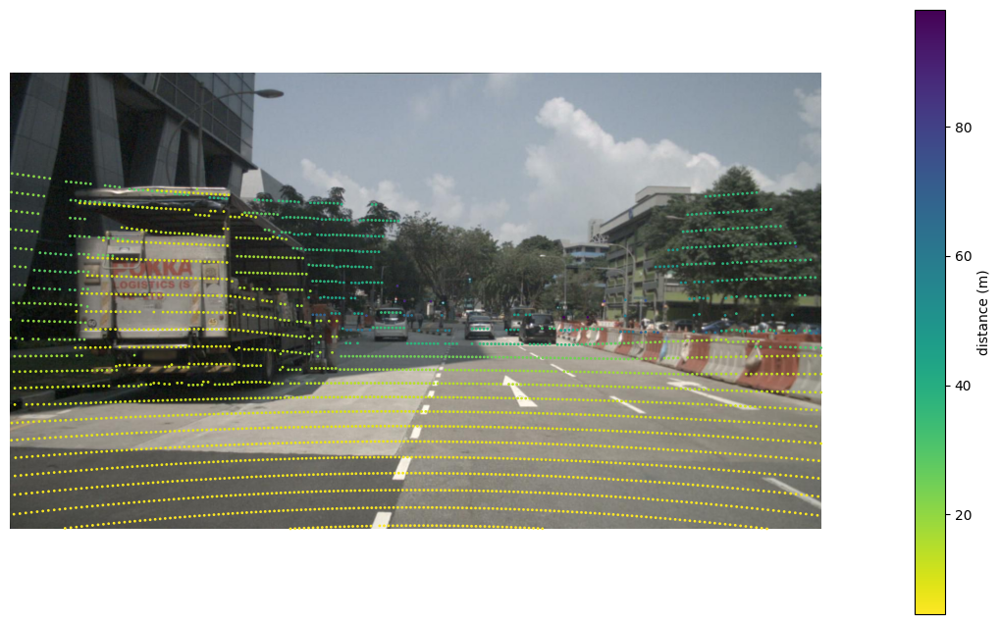

In [20]:
# Vérification : points lidar projetés sur l'image CAM_FRONT (couleur = distance)
import matplotlib.pyplot as plt
t = load_tables(DATAROOT, VERSION)
by = lambda tab: {r['token']: r for r in tab}
sensors, calibs, poses = by(t['sensor']), by(t['calibrated_sensor']), by(t['ego_pose'])
chan = lambda sd: sensors[calibs[sd['calibrated_sensor_token']]['sensor_token']]['channel']
tok = t['scene'][0]['first_sample_token']
lid = next(sd for sd in t['sample_data'] if sd['sample_token'] == tok and sd['is_key_frame'] and chan(sd) == 'LIDAR_TOP')
cam = next(sd for sd in t['sample_data'] if sd['sample_token'] == tok and sd['is_key_frame'] and chan(sd) == 'CAM_FRONT')

p = np.fromfile(os.path.join(DATAROOT, lid['filename']), dtype=np.float32).reshape(-1, 5)[:, :3]
T_lid = get_T(poses[lid['ego_pose_token']]) @ get_T(calibs[lid['calibrated_sensor_token']])
T_cam = get_T(poses[cam['ego_pose_token']]) @ get_T(calibs[cam['calibrated_sensor_token']])
pw = p @ T_lid[:3, :3].T + T_lid[:3, 3]
pc = (np.c_[pw, np.ones(len(pw))] @ np.linalg.inv(T_cam).T)[:, :3]
pc = pc[pc[:, 2] > 0.5]
uv = pc @ np.array(calibs[cam['calibrated_sensor_token']]['camera_intrinsic']).T
u, v = uv[:, 0] / uv[:, 2], uv[:, 1] / uv[:, 2]
img = plt.imread(os.path.join(DATAROOT, cam['filename']))
ok = (u >= 0) & (u < img.shape[1]) & (v >= 0) & (v < img.shape[0])

plt.figure(figsize=(14, 8)); plt.imshow(img)
plt.scatter(u[ok], v[ok], c=pc[ok, 2], s=1, cmap='viridis_r')
plt.colorbar(label='distance (m)'); plt.axis('off'); plt.show()

In [21]:
# Entraînement de C (18 000 itérations), déjà fait dans une session précédente
# !ns-train splatfacto --data /kaggle/working/nerf_data_tvt_lidar --output-dir /kaggle/working/outputs --max-num-iterations 18000 --viewer.quit-on-train-completion True --pipeline.model.num-downscales 2 nerfstudio-data

In [22]:
# # Expérience 4 : sans lidar (exp. 5, checkpoint 18 000) contre avec lidar (C, 18 000 itérations)
# import os, glob, torch, pandas as pd
# from pathlib import Path
# os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'
# from nerfstudio.utils.eval_utils import eval_setup

# run_rand  = sorted(glob.glob('/kaggle/working/outputs/nerf_data_tvt/splatfacto/*/'))[-1]
# run_lidar = sorted(glob.glob('/kaggle/working/outputs/nerf_data_tvt_lidar/splatfacto/*/'))[-1]
# modeles = {
#     'Sans lidar (18k)': (run_rand,  run_rand  + 'nerfstudio_models/step-000018000.ckpt'),
#     'Avec lidar (18k)': (run_lidar, sorted(glob.glob(run_lidar + 'nerfstudio_models/*.ckpt'))[-1]),
# }

# def evaluate(run, ckpt, mode):
#     """Charge un seul checkpoint précis et l'évalue sur 'val' ou 'test'."""
#     _, pipe, _, _ = eval_setup(Path(run) / 'config.yml', test_mode=mode)
#     sd = torch.load(ckpt, map_location='cpu', weights_only=False)
#     pipe.load_pipeline(sd['pipeline'], sd['step']); pipe.eval()
#     m = pipe.get_average_eval_image_metrics(step=sd['step'])
#     n = pipe.model.num_points
#     del pipe; torch.cuda.empty_cache()
#     return {'PSNR ↑': float(m['psnr']), 'SSIM ↑': float(m['ssim']), 'LPIPS ↓': float(m['lpips'])}, n

# for mode in ['val', 'test']:
#     lignes = {}
#     for label, (run, ckpt) in modeles.items():
#         metr, n = evaluate(run, ckpt, mode)
#         lignes[label] = {**metr, 'Gaussiennes': n}
#         print(f'{mode} | {label} | {os.path.basename(ckpt)}')
#     df = pd.DataFrame(lignes).T
#     df.loc['Écart (lidar − sans)'] = df.iloc[1] - df.iloc[0]
#     print(f'\n=== {mode.upper()} ===')
#     display(df.round(3))

### Résultat
| Jeu | Modèle | PSNR ↑ | SSIM ↑ | LPIPS ↓ | Gaussiennes |
|---|---|---|---|---|---|
| Validation | Sans lidar (18k) | 19.971 | 0.737 | 0.501 | 444 921 |
| Validation | Avec lidar (18k) | 19.924 | 0.746 | **0.455** | 512 224 |
| Test | Sans lidar (18k) | **20.905** | 0.750 | 0.457 | 444 921 |
| Test | Avec lidar (18k) | 20.103 | 0.751 | **0.447** | 512 224 |



### Analyse
- **LPIPS** : meilleur avec le lidar sur les deux jeux (−0,045 en validation, soit environ 9 % ; −0,010 en test).
  C'est le seul effet **cohérent** entre validation et test : le rendu avec lidar est perçu comme plus fidèle.
- **SSIM** : légèrement meilleur ou égal avec le lidar (+0,010 en validation, +0,001 en test).
- **PSNR** : identique en validation (−0,05 dB), mais −0,8 dB en test. Comme cette baisse n'apparaît pas en
  validation, elle est probablement en partie due au **hasard d'un entraînement unique** et à la petite taille du
  test (8 endroits de la rue), plutôt qu'à un vrai défaut du lidar.
- **Gaussiennes** : +15 % avec le lidar. Partir de points posés sur les surfaces semble pousser la densification à
  garder davantage de détails, ce qui va dans le sens du meilleur LPIPS.
- **Pourquoi le gain reste modeste** : à 18 000 itérations, il se pourrait que la densification ait eu le temps de redistribuer les
  gaussiennes de l'initialisation aléatoire. Le nuage lidar ne couvre pas le ciel, ni ce qui est au-delà de 60 m,
  et contient des traînées dues aux objets en mouvement.

### Conclusion
À 18 000 itérations, l'initialisation par le lidar **n'améliore pas la précision pixel par pixel** (PSNR), mais
améliore **la qualité perçue** (LPIPS) de façon cohérente sur validation et test.

### Questions
1. **Le lidar fait-il apprendre plus vite ?** Avec un bon point de départ, le modèle atteint peut-être son
   meilleur score avant 18 000 itérations. Pour le savoir, il faudrait entraîner C en sauvegardant des
   checkpoints, comme dans l'expérience 5, et comparer les deux courbes de validation.
2. **La différence est-elle réelle ou due à la chance ?** Deux entraînements identiques ne donnent jamais
   exactement le même score. Il faudrait relancer chaque version 2 ou 3 fois et comparer les moyennes.
3. **Un meilleur nuage lidar aiderait-il plus ?** Par exemple en retirant les points des voitures qui bougent,
   ou en utilisant tous les balayages lidar au lieu de 39.
4. **Le lidar aide-t-il plus quand on s'éloigne de la trajectoire ?** Les images de test sont proches de celles
   d'entraînement. En décalant la caméra d'un ou deux mètres sur le côté, une mauvaise géométrie se verrait
   beaucoup plus : c'est là que le lidar pourrait faire la différence.

## Expérience 6 : quel nuage lidar pour initialiser les gaussiennes ?

Je compare trois nuages, et chaque version ne change qu'une chose par rapport à la précédente :

- L1 : balayages lidar des 39 keyframes, objets mobiles gardés (c'est le nuage du modèle C) ;
- L2 : balayages des 39 keyframes, objets mobiles retirés ;
- L3 : tous les balayages (keyframes et sweeps), objets mobiles retirés.

Les objets mobiles sont repérés grâce aux boîtes 3D annotées de nuScenes (attribut « moving »), interpolées entre les keyframes.

La comparaison de L1 et L2 mesure l'effet du retrait des objets mobiles, celle de L2 et L3 l'effet de la densité. Pour chaque nuage, je trace les courbes d'entraînement et de validation (un checkpoint toutes les 2000 itérations, jusqu'à 18 000) et je mesure le coût.

In [23]:
# Tables nuScenes et index utiles pour l'expérience 6
import os, json, time
import numpy as np
import pandas as pd

t = load_tables(DATAROOT, VERSION)
by_token = lambda table: {r['token']: r for r in table}

sensors     = by_token(t['sensor'])
calibs      = by_token(t['calibrated_sensor'])
poses       = by_token(t['ego_pose'])
samples     = by_token(t['sample'])
sample_data = by_token(t['sample_data'])

def channel(sd):
    """Nom du capteur d'une capture (ex. 'LIDAR_TOP', 'CAM_FRONT')."""
    return sensors[calibs[sd['calibrated_sensor_token']]['sensor_token']]['channel']

def scene_chain(scene_idx, chan):
    """Toutes les captures (keyframes + sweeps) d'un capteur dans une scène, dans l'ordre du temps."""
    first_sample = t['scene'][scene_idx]['first_sample_token']
    sd = next(s for s in t['sample_data']
              if s['sample_token'] == first_sample and s['is_key_frame'] and channel(s) == chan)
    chain = []
    while sd:                       # on suit la chaîne 'next' jusqu'à la fin de la scène
        chain.append(sd)
        sd = sample_data.get(sd['next'])
    return chain

lidar_chain = scene_chain(0, 'LIDAR_TOP')
cam_chain   = scene_chain(0, 'CAM_FRONT')
print(f"LIDAR_TOP : {len(lidar_chain)} balayages, dont {sum(s['is_key_frame'] for s in lidar_chain)} keyframes")
print(f"CAM_FRONT : {len(cam_chain)} images")

LIDAR_TOP : 382 balayages, dont 39 keyframes
CAM_FRONT : 224 images


In [24]:
# Fonctions géométriques

def lidar_to_world(sd, r_min=3.0, r_max=60.0):
    """Lit un balayage lidar et renvoie ses points dans le repère monde, tableau (N, 3)."""
    pts = np.fromfile(os.path.join(DATAROOT, sd['filename']), dtype=np.float32).reshape(-1, 5)[:, :3]
    # On retire la carrosserie de la voiture (< 3 m) et le très lointain (> 60 m)
    dist = np.linalg.norm(pts[:, :2], axis=1)
    pts = pts[(dist > r_min) & (dist < r_max)]
    # lidar vers voiture (calibration), puis voiture vers monde (pose de la voiture à l'instant du balayage)
    T = get_T(poses[sd['ego_pose_token']]) @ get_T(calibs[sd['calibrated_sensor_token']])
    return pts @ T[:3, :3].T + T[:3, 3]


def project_to_camera(pw, cam_sd):
    """Projette des points monde dans une image caméra, en convention OpenCV (celle de nuScenes).
    Renvoie : indices des points visibles, et leurs pixels (u, v)."""
    T_cam = get_T(poses[cam_sd['ego_pose_token']]) @ get_T(calibs[cam_sd['calibrated_sensor_token']])
    pc = (np.c_[pw, np.ones(len(pw))] @ np.linalg.inv(T_cam).T)[:, :3]   # monde vers caméra
    K = np.array(calibs[cam_sd['calibrated_sensor_token']]['camera_intrinsic'])

    front = np.flatnonzero(pc[:, 2] > 0.5)          # devant la caméra (z > 0,5 m)
    uv = pc[front] @ K.T                             # projection : u = fx·x/z + cx, v = fy·y/z + cy
    u = (uv[:, 0] / uv[:, 2]).astype(int)
    v = (uv[:, 1] / uv[:, 2]).astype(int)
    inside = (u >= 0) & (u < cam_sd['width']) & (v >= 0) & (v < cam_sd['height'])
    return front[inside], u[inside], v[inside]


cam_times = np.array([s['timestamp'] for s in cam_chain])

def nearest_camera(timestamp):
    """Image CAM_FRONT la plus proche dans le temps (sert à colorier les points d'un balayage)."""
    return cam_chain[int(np.argmin(np.abs(cam_times - timestamp)))]

In [25]:
# Objets mobiles : boîtes 3D annotées dans nuScenes
attributes  = {a['token']: a['name'] for a in json.load(open(f'{DATAROOT}/{VERSION}/attribute.json'))}
annotations = json.load(open(f'{DATAROOT}/{VERSION}/sample_annotation.json'))

def is_moving(ann):
    """Un objet est 'mobile' si l'un de ses attributs se termine par '.moving'
    (vehicle.moving, pedestrian.moving, ...). Les voitures garées sont gardées."""
    return any(attributes[a].endswith('.moving') for a in ann['attribute_tokens'])

# Boîtes mobiles par keyframe : {sample_token: {instance_token: annotation}}
moving_by_sample = {}
for ann in annotations:
    if is_moving(ann):
        moving_by_sample.setdefault(ann['sample_token'], {})[ann['instance_token']] = ann

key_samples = [samples[s['sample_token']] for s in lidar_chain if s['is_key_frame']]
key_times   = np.array([s['timestamp'] for s in key_samples])


def slerp(q0, q1, a):
    """Interpolation sphérique entre deux quaternions [w, x, y, z], a dans [0, 1]."""
    q0, q1 = np.array(q0, float), np.array(q1, float)
    if np.dot(q0, q1) < 0:                     # prendre le plus court chemin
        q1 = -q1
    d = np.clip(np.dot(q0, q1), -1, 1)
    if d > 0.9995:                             # quasi identiques : interpolation linéaire suffit
        q = q0 + a * (q1 - q0)
    else:
        th = np.arccos(d)
        q = (np.sin((1 - a) * th) * q0 + np.sin(a * th) * q1) / np.sin(th)
    return q / np.linalg.norm(q)


def moving_boxes_at(timestamp):
    """Boîtes (centre, quaternion, taille) des objets mobiles à un instant donné.
    Aux keyframes : boîtes annotées. Entre deux keyframes : interpolées
    (position linéaire, rotation sphérique). Objet vu à une seule keyframe : sa boîte telle quelle."""
    i = np.searchsorted(key_times, timestamp)
    prev = key_samples[max(i - 1, 0)]
    nxt  = key_samples[min(i, len(key_samples) - 1)]
    span = nxt['timestamp'] - prev['timestamp']
    a = 0.0 if span == 0 else float(np.clip((timestamp - prev['timestamp']) / span, 0, 1))

    A = moving_by_sample.get(prev['token'], {})
    B = moving_by_sample.get(nxt['token'], {})
    boxes = []
    for inst in set(A) | set(B):
        if inst in A and inst in B:
            center = (1 - a) * np.array(A[inst]['translation']) + a * np.array(B[inst]['translation'])
            quat   = slerp(A[inst]['rotation'], B[inst]['rotation'], a)
            size   = A[inst]['size']
        else:
            ann = A.get(inst) or B.get(inst)
            center, quat, size = np.array(ann['translation']), ann['rotation'], ann['size']
        boxes.append((center, quat, size))
    return boxes


def outside_boxes(pw, boxes, margin=0.3):
    """Masque des points situés hors de toutes les boîtes (agrandies de `margin` mètres)."""
    keep = np.ones(len(pw), bool)
    for center, quat, (w, l, h) in boxes:        # taille nuScenes : largeur, longueur, hauteur
        R = quat_to_rotmat(quat)
        local = (pw - center) @ R                  # coordonnées dans le repère de la boîte
        inside = ((np.abs(local[:, 0]) <= l / 2 + margin) &
                  (np.abs(local[:, 1]) <= w / 2 + margin) &
                  (np.abs(local[:, 2]) <= h / 2 + margin))
        keep &= ~inside
    return keep

In [26]:

# Construction d'un nuage lidar fusionné et colorié
import open3d as o3d
from PIL import Image

def build_lidar_cloud(out_ply, use_sweeps, remove_moving, voxel=0.15):
    """Fusionne des balayages lidar dans le repère monde, retire (ou non) les objets mobiles,
    colorie les points avec CAM_FRONT, sous-échantillonne, et enregistre un .ply.
    Renvoie des statistiques de coût."""
    t0 = time.time()
    sweeps = lidar_chain if use_sweeps else [s for s in lidar_chain if s['is_key_frame']]

    pts_all, col_all = [], []
    n_raw, n_removed = 0, 0
    for sd in sweeps:
        pw = lidar_to_world(sd)
        n_raw += len(pw)

        if remove_moving:                                     # retrait des objets mobiles
            keep = outside_boxes(pw, moving_boxes_at(sd['timestamp']))
            n_removed += int((~keep).sum())
            pw = pw[keep]

        cam = nearest_camera(sd['timestamp'])                 # image la plus proche dans le temps
        idx, u, v = project_to_camera(pw, cam)                # points vus par CAM_FRONT
        img = np.asarray(Image.open(os.path.join(DATAROOT, cam['filename'])).convert('RGB'))
        pts_all.append(pw[idx])
        col_all.append(img[v, u])                              # couleur du pixel où tombe le point

    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(np.concatenate(pts_all))
    pcd.colors = o3d.utility.Vector3dVector(np.concatenate(col_all) / 255.0)
    n_before = len(pcd.points)
    pcd = pcd.voxel_down_sample(voxel)                         # un point par cube de 15 cm
    o3d.io.write_point_cloud(out_ply, pcd)

    return {'balayages': len(sweeps), 'points bruts': n_raw, 'points mobiles retirés': n_removed,
            'points vus par la caméra': n_before, 'points finaux (après voxel)': len(pcd.points),
            'temps (s)': round(time.time() - t0, 1)}

In [27]:
# Construction de L1, L2, L3
versions = {
    'L1': dict(use_sweeps=False, remove_moving=False),   # = nuage de C
    'L2': dict(use_sweeps=False, remove_moving=True),
    'L3': dict(use_sweeps=True,  remove_moving=True),
}

os.makedirs('/kaggle/working/lidar_clouds', exist_ok=True)
stats = {}
for name, cfg in versions.items():
    stats[name] = build_lidar_cloud(f'/kaggle/working/lidar_clouds/{name}.ply', **cfg)
    print(name, 'terminé')

df_stats = pd.DataFrame(stats).T
df_stats.to_csv('/kaggle/working/lidar_clouds/stats.csv')     # garder les chiffres en fichier
display(df_stats)

L1 terminé
L2 terminé
L3 terminé


,balayages,points bruts,points mobiles retirés,points vus par la caméra,points finaux (après voxel),temps (s)
L1,39.0,978602.0,0.0,114182.0,63536.0,0.6
L2,39.0,978602.0,16592.0,103351.0,58141.0,1.1
L3,382.0,9588581.0,160875.0,989563.0,240207.0,11.9


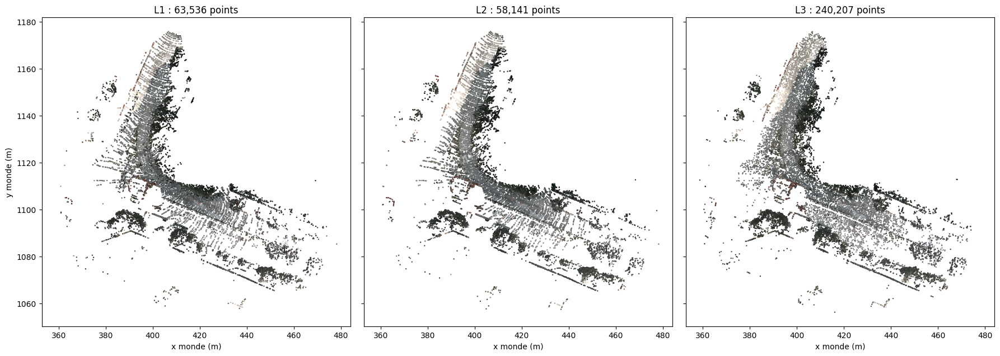

In [28]:
# Les trois nuages vus du dessus (20 000 points tirés au hasard chacun)
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
rng = np.random.default_rng(0)
for ax, name in zip(axes, versions):
    pcd = o3d.io.read_point_cloud(f'/kaggle/working/lidar_clouds/{name}.ply')
    P, C = np.asarray(pcd.points), np.asarray(pcd.colors)
    sel = rng.choice(len(P), size=min(20000, len(P)), replace=False)
    ax.scatter(P[sel, 0], P[sel, 1], c=C[sel], s=0.5)
    ax.set_title(f'{name} : {len(P):,} points')
    ax.set_aspect('equal'); ax.set_xlabel('x monde (m)')
axes[0].set_ylabel('y monde (m)')
plt.tight_layout(); plt.show()

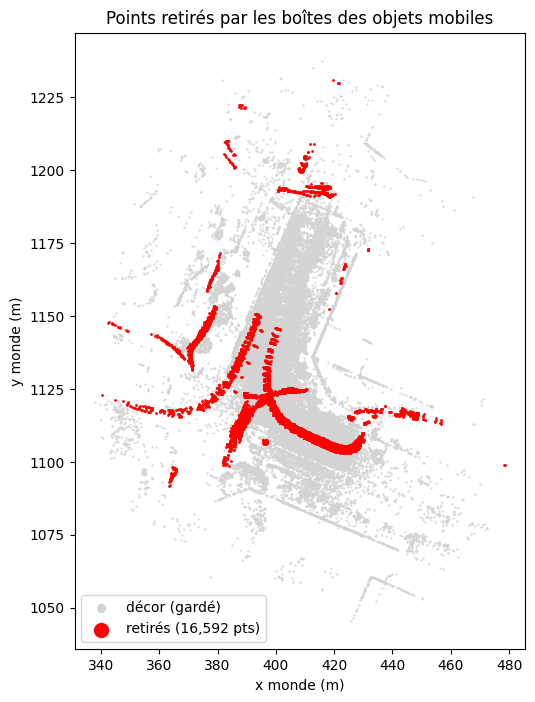

In [29]:
# Vérification : où sont les points retirés (objets mobiles) ?
# On refait le parcours des 39 keyframes, mais on garde les points supprimés pour les afficher.
removed = []
kept = []
for sd in lidar_chain:
    if not sd['is_key_frame']:
        continue
    pw = lidar_to_world(sd)
    keep = outside_boxes(pw, moving_boxes_at(sd['timestamp']))
    removed.append(pw[~keep])     # points dans une boîte d'objet mobile
    kept.append(pw[keep][::20])   # 1 point sur 20 suffit pour le décor

removed = np.concatenate(removed)
kept = np.concatenate(kept)

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(kept[:, 0], kept[:, 1], s=0.3, c='lightgray', label='décor (gardé)')
ax.scatter(removed[:, 0], removed[:, 1], s=1, c='red', label=f'retirés ({len(removed):,} pts)')
ax.set_aspect('equal')
ax.legend(markerscale=10)
ax.set_title('Points retirés par les boîtes des objets mobiles')
ax.set_xlabel('x monde (m)')
ax.set_ylabel('y monde (m)')
plt.show()

In [30]:
# Un transforms.json par nuage, dans le dossier nerf_data_tvt
# On ne copie pas les images : les trois fichiers pointent vers les mêmes images
# et les mêmes découpages train / val / test. Seul le nuage d'initialisation change.
import shutil

DATA = '/kaggle/working/nerf_data_tvt'
base = json.load(open(f'{DATA}/transforms.json'))

for name in ['L1', 'L2', 'L3']:
    # 1) Copier le nuage à côté des images (nerfstudio le cherche relativement au dossier)
    shutil.copy(f'/kaggle/working/lidar_clouds/{name}.ply', f'{DATA}/{name}.ply')

    # 2) Même contenu que transforms.json, mais avec le nuage lidar en initialisation
    tj = dict(base)
    tj['ply_file_path'] = f'{name}.ply'
    json.dump(tj, open(f'{DATA}/transforms_{name}.json', 'w'), indent=2)

    print(name, ':', len(tj['train_filenames']), 'train |',
          len(tj['val_filenames']), 'val |', len(tj['test_filenames']), 'test')

L1 : 125 train | 47 val | 52 test
L2 : 125 train | 47 val | 52 test
L3 : 125 train | 47 val | 52 test


In [31]:
# # Lancer un entraînement en arrière-plan, sur un GPU choisi
# import subprocess

# def launch(name, gpu):
#     """Entraîne splatfacto 18 000 itérations avec le nuage `name`, sur le GPU `gpu`.
#     Checkpoint toutes les 2 000 itérations (tous gardés).
#     Le temps d'entraînement est écrit dans logs/exp6_{name}_seconds.txt."""
#     os.makedirs('/kaggle/working/logs', exist_ok=True)
#     log = f'/kaggle/working/logs/exp6_{name}'

#     ns_train = (
#         f'ns-train splatfacto '
#         f'--data {DATA}/transforms_{name}.json '
#         f'--experiment-name exp6_{name} '
#         f'--max-num-iterations 18000 '
#         f'--steps-per-save 2000 '
#         f'--save-only-latest-checkpoint False '
#         f'--viewer.quit-on-train-completion True'
#     )
#     # Petit script bash : chronomètre autour de ns-train
#     script = f"""
#     start=$(date +%s)
#     {ns_train}
#     end=$(date +%s)
#     echo $((end - start)) > {log}_seconds.txt
#     """
#     env = dict(os.environ, CUDA_VISIBLE_DEVICES=str(gpu))   # un run = un GPU
#     return subprocess.Popen(['bash', '-c', script], env=env,
#                             stdout=open(f'{log}.log', 'w'), stderr=subprocess.STDOUT)

In [32]:
# # Kaggle donne 2 GPU T4 : on lance L1 sur le GPU 0 et L2 sur le GPU 1
# procs = {
#     'L1': launch('L1', gpu=0),
#     'L2': launch('L2', gpu=1),
# }

In [33]:
# # Lancer L3 seulement quand L1 est terminé (état 0 dans la cellule de suivi ci-dessous)
# procs['L3'] = launch('L3', gpu=0)

In [34]:
# # État des runs : None = en cours, 0 = fini sans erreur, autre = erreur
# for name, p in procs.items():
#     print(f'=== {name} : état {p.poll()} ===')
#     lines = open(f'/kaggle/working/logs/exp6_{name}.log').read().splitlines()
#     print('\n'.join(lines[-3:]))   # 3 dernières lignes du log

In [35]:
# Temps total d'entraînement (secondes), écrit par le script bash
for name in ['L1', 'L2', 'L3']:
    s = int(open(f'/kaggle/working/logs/exp6_{name}_seconds.txt').read())
    print(f'{name} : {s // 60} min {s % 60} s')

L1 : 19 min 59 s
L2 : 19 min 42 s
L3 : 19 min 7 s


In [36]:
# Dossiers des trois runs et liste de leurs checkpoints
import glob, torch
from pathlib import Path

os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'   # sinon torch.load refuse les checkpoints
from nerfstudio.utils.eval_utils import eval_setup

def find_run(name):
    """Dernier run de l'expérience exp6_{name} (dossier contenant config.yml)."""
    runs = sorted(glob.glob(f'/kaggle/working/outputs/exp6_{name}/splatfacto/*/'))
    return Path(runs[-1])

# for name in ['L1', 'L2', 'L3']:
#     ckpts = sorted(glob.glob(str(find_run(name) / 'nerfstudio_models/step-*.ckpt')))
#     print(name, ':', [Path(c).stem for c in ckpts])

/usr/local/lib/python3.12/dist-packages/nerfstudio/field_components/activations.py:32: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd(cast_inputs=torch.float32)
/usr/local/lib/python3.12/dist-packages/nerfstudio/field_components/activations.py:38: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd


In [37]:
# Métriques moyennes sur les 125 images de train
# nerfstudio ne sait évaluer que val ou test ; pour train, on boucle nous-mêmes.
def train_metrics(pipeline):
    pipeline.eval()      # mode évaluation : rendu seul, sans densification
                         # (la mesure sur val remet le modèle en mode entraînement à la fin)
    dm, model = pipeline.datamanager, pipeline.model
    cameras = dm.train_dataset.cameras
    scores = []
    with torch.no_grad():
        for i in range(len(cameras)):
            camera = cameras[i:i + 1].to(model.device)
            outputs = model.get_outputs_for_camera(camera)       # rendu de la vue i
            batch = {'image': dm.cached_train[i]['image']}       # vraie image i
            metrics, _ = model.get_image_metrics_and_images(outputs, batch)
            scores.append(metrics)
    return {k: float(np.mean([s[k] for s in scores])) for k in ['psnr', 'ssim', 'lpips']}

In [38]:
# Pour un run : charger chaque checkpoint et mesurer train + val
def curves_for(name):
    run = find_run(name)
    _, pipeline, _, _ = eval_setup(run / 'config.yml', test_mode='val')
    rows = []
    for ckpt in sorted(glob.glob(str(run / 'nerfstudio_models/step-*.ckpt'))):
        sd = torch.load(ckpt, map_location='cpu')
        pipeline.load_pipeline(sd['pipeline'], sd['step'])      # charge les gaussiennes de ce checkpoint
        pipeline.eval()

        val = pipeline.get_average_eval_image_metrics(step=sd['step'])
        train = train_metrics(pipeline)
        rows.append({
            'step': sd['step'],
            'n_gaussians': int(pipeline.model.means.shape[0]),
            **{f'train_{k}': v for k, v in train.items()},
            **{f'val_{k}': float(val[k]) for k in ['psnr', 'ssim', 'lpips']},
        })
        print(name, sd['step'], f"val PSNR {rows[-1]['val_psnr']:.2f}")

    del pipeline
    torch.cuda.empty_cache()     # libérer le GPU avant le run suivant
    return rows

In [39]:
# # Calcul pour L1, L2, L3 (quelques minutes par run)
# curves = {name: curves_for(name) for name in ['L1', 'L2', 'L3']}
# json.dump(curves, open('/kaggle/working/exp6_curves.json', 'w'), indent=2)

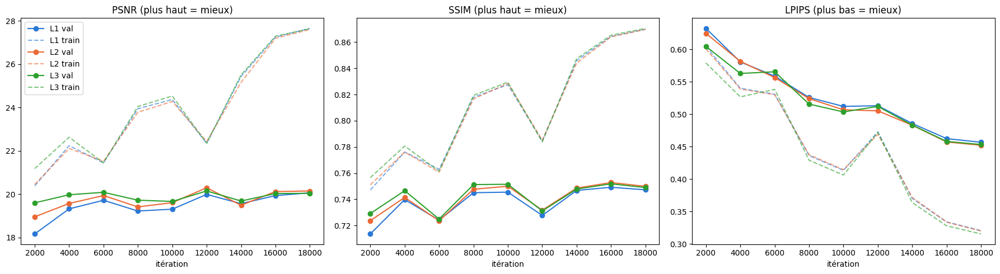

In [40]:
# Graphiques de l'expérience 6, relus depuis le fichier (aucun recalcul)
import json
import matplotlib.pyplot as plt

curves = json.load(open('/kaggle/working/exp6_curves.json'))

# Une couleur par nuage ; trait plein = val, pointillés = train
colors = {'L1': '#2a78d6', 'L2': '#eb6834', 'L3': '#2ca02c'}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metric in zip(axes, ['psnr', 'ssim', 'lpips']):
    for name, rows in curves.items():
        steps = [r['step'] for r in rows]
        ax.plot(steps, [r[f'val_{metric}'] for r in rows], '-o', c=colors[name], label=f'{name} val')
        ax.plot(steps, [r[f'train_{metric}'] for r in rows], '--', c=colors[name], alpha=0.6, label=f'{name} train')
    ax.set_title(metric.upper() + (' (plus bas = mieux)' if metric == 'lpips' else ' (plus haut = mieux)'))
    ax.set_xlabel('itération')
axes[0].legend()
plt.tight_layout()
plt.savefig('/kaggle/working/exp6_curves.png', dpi=120)
plt.show()

### Analyse
1. **Un meilleur nuage aide au début.** À 2 000 itérations, retirer les objets mobiles fait gagner ≈ 0,8 dB (L1 → L2), et densifier encore ≈ 0,6 dB (L2 → L3).
2. **L'avantage disparaît vers 6 000 itérations.** À 18 000, les écarts sont inférieurs à 0,2 dB. Avec une seule exécution par nuage, on ne peut pas les distinguer du bruit.
3. **Le coût ne change presque pas.** L3 part avec 4× plus de points mais met le même temps : la densification ajuste ensuite le nombre de gaussiennes selon les images.
4. **Fort surapprentissage.** À 18k, PSNR train ≈ 27,6 contre ≈ 20 en val : le modèle mémorise les images d'entraînement. La val ne progresse plus que lentement après ≈ 4 000 itérations (≈ +0,5 dB jusqu'à 18k).
5. **LPIPS val baisse jusqu'au bout** (≈ 0,63 → 0,45) : les images deviennent plus nettes même quand le PSNR ne bouge plus.
6. **Les creux à 6 000 et 12 000 sont un artefact de mesure.** Toutes les 3 000 itérations (`reset_alpha_every 30 × refine_every 100`), splatfacto plafonne l'opacité de toutes les gaussiennes. Celles qui ne regagnent pas d'opacité sont ensuite supprimées : c'est un « grand ménage » contre les gaussiennes inutiles. Juste après, le modèle est temporairement moins bon. Ce ménage s'arrête à 15 000 (`stop_split_at`). Les checkpoints à 6 000 et 12 000 tombent pile dessus. L'effet est fort sur les courbes **train**, faible sur le PSNR **val**.

### Conclusion
- Un **meilleur nuage lidar** (objets mobiles retirés, sweeps ajoutés) **accélère le début** de l'apprentissage, mais **ne change pas le résultat final**.
- Retirer les objets mobiles et ajouter les sweeps **ne coûte presque rien** : on garde L3 par défaut.
- Ce qui limite le modèle aujourd'hui, ce n'est pas l'initialisation : c'est le **surapprentissage**.

### Note sur l'expérience 5
L'expérience 5 sauvegardait toutes les 3 000 itérations. Avant 15 000, chaque checkpoint tombait pile sur un reset d'opacité (le « ménage »).
- **Courbe train : faussée.** Le saut entre 12k et 15k n'est pas un apprentissage soudain : 15k est le premier point mesuré hors reset. Le surapprentissage commençait donc plus tôt que la courbe ne le montrait.
- **Courbe val : peu touchée.** Dans l'expérience 6, le PSNR val ne chute pas aux points de reset. La conclusion « la val plafonne vers 18k » reste valable.

**Leçon**:

On fait du l’early stopping (arrêt précoce), qui consiste à choisir le modèle sur la validation. Concrètement, on retient :

Un plafond : 18 000 itérations. Au-delà, la val ne bouge plus (l’expérience 5 l’a montré jusqu’à 30k). Inutile de dépenser du GPU après.
Des sauvegardes régulières, mais pas sur les resets. Les resets tombent à 3k, 6k, 9k et 12k. Avec --steps-per-save 2000, on tombe encore dessus à 6k et 12k. --steps-per-save 2500 les évite tous : 2 500, 5 000, 7 500, 10 000, 12 500, 15 000 (15 000 n’est plus un reset).
On garde le checkpoint qui a le meilleur score val. Si plusieurs sont à égalité, à 0,1 dB près, on prend le plus tôt : il a moins surappris.

### Questions
1. Comment se comportent-ils sur de **vraies nouvelles vues** (CAM_FRONT_LEFT) ?
2. Comment réduire le surapprentissage : plus de vues, d'autres caméras, régularisation ?

## Expérience 7 : apprendre la scène avec les trois caméras avant

J'entraîne le modèle sur `CAM_FRONT_LEFT`, `CAM_FRONT` et `CAM_FRONT_RIGHT`, en l'initialisant avec un nuage L3 construit pour couvrir les champs de vision des trois caméras. Chaque caméra est découpée avec la même règle que `nerf_data_tvt`. Le plan : entraîner, choisir le checkpoint sur la validation à partir des courbes, puis décaler les caméras de test pour juger les nouvelles vues.

In [41]:
# Imports nécessaires à l'expérience 7 (à relancer après chaque redémarrage)
import open3d as o3d
import matplotlib.pyplot as plt
from PIL import Image
import shutil, subprocess

rng = np.random.default_rng(0)

In [42]:
# Images (keyframes + sweeps) des 3 caméras avant
CAMS = ['CAM_FRONT_LEFT', 'CAM_FRONT', 'CAM_FRONT_RIGHT']
chains = {cam: scene_chain(0, cam) for cam in CAMS}

for cam, chain in chains.items():
    print(f'{cam:16s} {len(chain)} images, dont {sum(s["is_key_frame"] for s in chain)} keyframes')

CAM_FRONT_LEFT   224 images, dont 39 keyframes
CAM_FRONT        224 images, dont 39 keyframes
CAM_FRONT_RIGHT  217 images, dont 39 keyframes


In [43]:
# Même règle que nerf_data_tvt, appliquée à chaque caméra
# Keyframe n°i : test si i % 5 == 2, val si i % 5 == 4, sinon train.
# Une image sweep prend le groupe de sa keyframe la plus proche, si elle est à moins de 0,25 s ; sinon train.
def split_of_chain(chain):
    keys = [s for s in chain if s['is_key_frame']]
    key_times = np.array([s['timestamp'] for s in keys])
    key_label = ['test' if i % 5 == 2 else 'val' if i % 5 == 4 else 'train' for i in range(len(keys))]

    labels = []
    for s in chain:
        j = int(np.argmin(np.abs(key_times - s['timestamp'])))      # keyframe la plus proche
        close = abs(key_times[j] - s['timestamp']) <= 0.25e6         # timestamps en microsecondes
        labels.append(key_label[j] if (s['is_key_frame'] or close) else 'train')
    return labels

In [44]:
# Dossier nerf_data_3cams : images + transforms.json (paramètres internes par image)
OUT3 = '/kaggle/working/nerf_data_3cams'
os.makedirs(f'{OUT3}/images', exist_ok=True)

frames = []
splits = {'train': [], 'val': [], 'test': []}
for cam, chain in chains.items():
    for s, label in zip(chain, split_of_chain(chain)):
        name = f"images/{s['token']}.jpg"
        shutil.copy(os.path.join(DATAROOT, s['filename']), f'{OUT3}/{name}')

        # Pose caméra vers monde, convertie en OpenGL (comme avant)
        c2w = get_T(poses[s['ego_pose_token']]) @ get_T(calibs[s['calibrated_sensor_token']]) @ OPENCV_TO_OPENGL
        K = calibs[s['calibrated_sensor_token']]['camera_intrinsic']
        frames.append({
            'file_path': name,
            'transform_matrix': c2w.tolist(),
            # chaque caméra a sa propre focale et son propre centre
            'fl_x': K[0][0], 'fl_y': K[1][1], 'cx': K[0][2], 'cy': K[1][2],
            'w': s['width'], 'h': s['height'],
        })
        splits[label].append(name)

tj3 = {'camera_model': 'OPENCV', 'frames': frames,
       'train_filenames': splits['train'], 'val_filenames': splits['val'], 'test_filenames': splits['test']}
json.dump(tj3, open(f'{OUT3}/transforms.json', 'w'), indent=2)
print({k: len(v) for k, v in splits.items()})

{'train': 400, 'val': 122, 'test': 143}


In [45]:
# Même recette que L3, mais un point est gardé s'il est vu par au moins une des 3 caméras
cam_times = {cam: np.array([s['timestamp'] for s in chain]) for cam, chain in chains.items()}

def build_cloud_3cams(out_ply, voxel=0.15):
    t0 = time.time()
    pts_all, col_all = [], []
    for sd in lidar_chain:                                       # les 382 balayages
        pw = lidar_to_world(sd)
        pw = pw[outside_boxes(pw, moving_boxes_at(sd['timestamp']))]   # objets mobiles retirés

        for cam in CAMS:                                         # chaque caméra colorie ce qu'elle voit
            cam_sd = chains[cam][int(np.argmin(np.abs(cam_times[cam] - sd['timestamp'])))]
            idx, u, v = project_to_camera(pw, cam_sd)
            img = np.asarray(Image.open(os.path.join(DATAROOT, cam_sd['filename'])).convert('RGB'))
            pts_all.append(pw[idx])
            col_all.append(img[v, u])

    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(np.concatenate(pts_all))
    pcd.colors = o3d.utility.Vector3dVector(np.concatenate(col_all) / 255.0)
    pcd = pcd.voxel_down_sample(voxel)        # fusionne aussi les points vus par deux caméras
    o3d.io.write_point_cloud(out_ply, pcd)
    print(f'{len(pcd.points):,} points, {time.time() - t0:.0f} s')

build_cloud_3cams(f'{OUT3}/L3_3cams.ply')
tj3['ply_file_path'] = 'L3_3cams.ply'
json.dump(tj3, open(f'{OUT3}/transforms.json', 'w'), indent=2)

511,108 points, 22 s


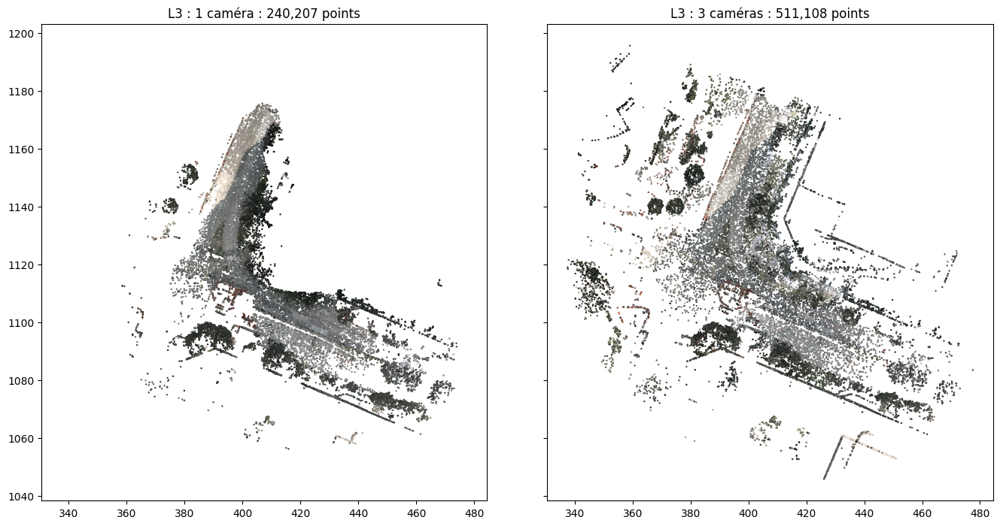

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)
for ax, (title, path) in zip(axes, [('L3 : 1 caméra', '/kaggle/working/lidar_clouds/L3.ply'),
                                     ('L3 : 3 caméras', f'{OUT3}/L3_3cams.ply')]):
    pcd = o3d.io.read_point_cloud(path)
    P, C = np.asarray(pcd.points), np.asarray(pcd.colors)
    sel = rng.choice(len(P), size=min(30000, len(P)), replace=False)
    ax.scatter(P[sel, 0], P[sel, 1], c=C[sel], s=0.5)
    ax.set_title(f'{title} : {len(P):,} points'); ax.set_aspect('equal')
plt.tight_layout(); plt.show()

In [47]:
# # 18 000 itérations, checkpoint toutes les 2 500 (jamais sur un reset), images stockées en uint8
# script = f"""
# start=$(date +%s)
# ns-train splatfacto \
#   --data {OUT3} \
#   --experiment-name exp7_3cams \
#   --max-num-iterations 18000 \
#   --steps-per-save 2500 \
#   --save-only-latest-checkpoint False \
#   --pipeline.datamanager.cache-images-type uint8 \
#   --viewer.quit-on-train-completion True
# end=$(date +%s)
# echo $((end - start)) > /kaggle/working/logs/exp7_seconds.txt
# """
# proc7 = subprocess.Popen(['bash', '-c', script], env=dict(os.environ, CUDA_VISIBLE_DEVICES='0'),
#                          stdout=open('/kaggle/working/logs/exp7.log', 'w'), stderr=subprocess.STDOUT)

In [48]:
# Run de l'expérience 7
import os, glob, json, torch
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'
from nerfstudio.utils.eval_utils import eval_setup

run7 = Path(sorted(glob.glob('/kaggle/working/outputs/exp7_3cams/splatfacto/*/'))[-1])
ckpts7 = sorted(glob.glob(str(run7 / 'nerfstudio_models/step-*.ckpt')))
print(run7.name, '|', len(ckpts7), 'checkpoints')

2026-10-21_160447 | 8 checkpoints


In [49]:
# Rendu + notes de chaque image d'un groupe (train ou val)
# Les images ont été nommées par leur token nuScenes : on retrouve ainsi leur caméra.
def per_image_metrics(pipeline, dataset, cached):
    pipeline.eval()                                   # rendu seul, sans densification
    model = pipeline.model
    rows = []
    with torch.no_grad():
        for i in range(len(dataset)):
            camera = dataset.cameras[i:i + 1].to(model.device)
            outputs = model.get_outputs_for_camera(camera)
            metrics, _ = model.get_image_metrics_and_images(outputs, {'image': cached[i]['image']})
            token = Path(dataset.image_filenames[i]).stem
            rows.append({'camera': channel(sample_data[token]),
                         'psnr': float(metrics['psnr']),
                         'ssim': float(metrics['ssim']),
                         'lpips': float(metrics['lpips'])})
    return pd.DataFrame(rows)

In [50]:
# # Pour chaque checkpoint : moyenne train, et moyenne val par caméra
# _, pipe7, _, _ = eval_setup(run7 / 'config.yml', test_mode='val')
# dm = pipe7.datamanager

# curves7 = []
# for ckpt in ckpts7:
#     sd = torch.load(ckpt, map_location='cpu')
#     pipe7.load_pipeline(sd['pipeline'], sd['step'])

#     tr = per_image_metrics(pipe7, dm.train_dataset, dm.cached_train)
#     va = per_image_metrics(pipe7, dm.eval_dataset, dm.cached_eval)

#     row = {'step': sd['step'], 'n_gaussians': int(pipe7.model.means.shape[0])}
#     for m in ['psnr', 'ssim', 'lpips']:
#         row[f'train_{m}'] = tr[m].mean()
#         row[f'val_{m}'] = va[m].mean()                                   # les 3 caméras
#         for cam, v in va.groupby('camera')[m].mean().items():            # caméra par caméra
#             row[f'val_{m}_{cam}'] = v
#     curves7.append(row)
#     print(sd['step'], f"val PSNR {row['val_psnr']:.2f} | LPIPS {row['val_lpips']:.3f}")

# json.dump(curves7, open('/kaggle/working/exp7_curves.json', 'w'), indent=2)

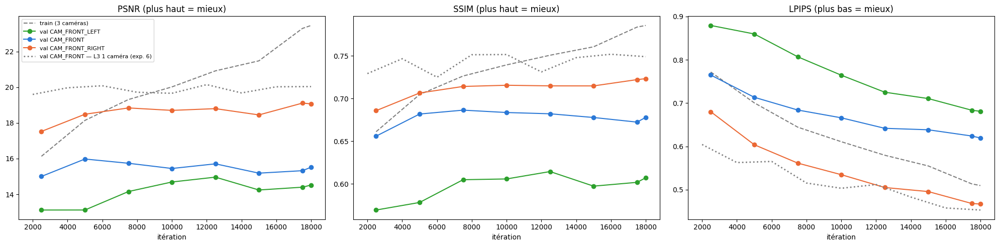

meilleur checkpoint (LPIPS val) : 17999 | 670614 gaussiennes


In [51]:
# Val par caméra, train, et référence : L3 à 1 caméra (exp. 6, val CAM_FRONT)
import json
import matplotlib.pyplot as plt

curves7 = json.load(open('/kaggle/working/exp7_curves.json'))
ref = json.load(open('/kaggle/working/exp6_curves.json'))['L3']
steps = [r['step'] for r in curves7]
colors = {'CAM_FRONT_LEFT': '#2ca02c', 'CAM_FRONT': '#2a78d6', 'CAM_FRONT_RIGHT': '#eb6834'}

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, m in zip(axes, ['psnr', 'ssim', 'lpips']):
    ax.plot(steps, [r[f'train_{m}'] for r in curves7], '--', c='black', alpha=0.5, label='train (3 caméras)')
    for cam, c in colors.items():
        ax.plot(steps, [r[f'val_{m}_{cam}'] for r in curves7], '-o', c=c, label=f'val {cam}')
    ax.plot([r['step'] for r in ref], [r[f'val_{m}'] for r in ref], ':', c='gray', lw=2,
            label='val CAM_FRONT — L3 1 caméra (exp. 6)')
    ax.set_title(m.upper() + (' (plus bas = mieux)' if m == 'lpips' else ' (plus haut = mieux)'))
    ax.set_xlabel('itération')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig('/kaggle/working/exp7_curves.png', dpi=120)
plt.show()

best7 = min(curves7, key=lambda r: r['val_lpips'])
print('meilleur checkpoint (LPIPS val) :', best7['step'], '|', best7['n_gaussians'], 'gaussiennes')

Il y a sans doutes plusieurs problèmes de validations dans ces courbes mais l'une particulièrement saute aux yeux :

Le modele L3, entrainé sur seuls les frames CAM_FRONT généralise mieux sur les données de validation de cette même caméra que le modèle exp7_3cams sur ces mêmes données.
Aussi la courbe orange est toujours au dessus des courbes bleue et verte ce qui suggère que le modele généralise mieux sur les images vu par la cam avant droit.
À nombre de passages égal par image, exp7_3cams apprend ses images d’entraînement aussi bien que L3, mais il généralise beaucoup moins bien sur la val CAM_FRONT (≈ 15,5 dB contre ≈ 20 dB).

Les causes possibles sont :

Exposition différente entre caméras : le même endroit a deux couleurs différentes selon la caméra. Le modèle fait un compromis qui est faux pour les deux. La cellule 38 la teste.


Calibration imparfaite entre caméras : si la position d’une caméra sur la voiture est légèrement fausse, le même objet n’est pas au même endroit selon la caméra. Le modèle le « dédouble » ou le rend flou. La cellule 35 la montrera : contours dédoublés.


Une scène plus large avec le même budget : même nombre d’itérations et mêmes réglages de densification pour 3 fois plus de surface, avec des bâtiments très proches à gauche, difficiles à apprendre. Ça coûte un peu, mais n’expliquerait pas une courbe plate.


Un bug dans l’export à 3 caméras : focale par image, découpage… Si le PSNR train de CAM_FRONT (cellule 34) est très bas alors que le contenu est le même que dans L3, c’est suspect.


Exposition à la lumière:

je vais afficher trois frames d'un même sample pour les cam_left, cam_front et cam_right, pour voir si on a quelque chose à l'oeil nu.

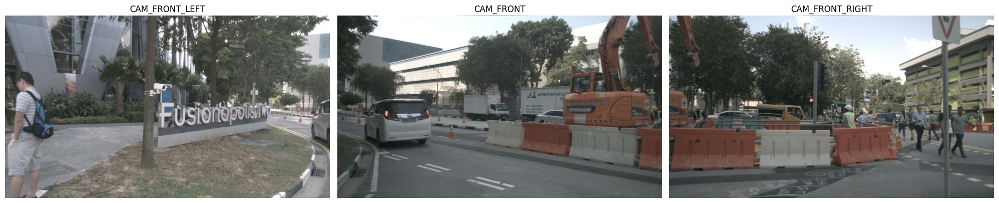

In [52]:
# Les 3 caméras au même instant (keyframe du milieu de la scène)
k = 19   # numéro de keyframe
fig, axes = plt.subplots(1, 3, figsize=(20, 4))
for ax, cam in zip(axes, CAMS):
    sd = [s for s in chains[cam] if s['is_key_frame']][k]
    ax.imshow(Image.open(os.path.join(DATAROOT, sd['filename'])))
    ax.set_title(cam); ax.axis('off')
plt.tight_layout(); plt.show()

J'ai l'impression que la caméra droite est plus proche en luminosité que la cam front. ALors que celle gauche semble bien plus éclairer.

In [53]:
# Pour chaque keyframe : points lidar vus par les deux caméras, et leur couleur dans chacune
def colors_seen_by_both(lidar_sd, camA, camB):
    pw = lidar_to_world(lidar_sd)
    pw = pw[outside_boxes(pw, moving_boxes_at(lidar_sd['timestamp']))]   # points fixes seulement

    cols = []
    for cam in (camA, camB):
        cam_sd = chains[cam][int(np.argmin(np.abs(cam_times[cam] - lidar_sd['timestamp'])))]
        idx, u, v = project_to_camera(pw, cam_sd)
        img = np.asarray(Image.open(os.path.join(DATAROOT, cam_sd['filename'])).convert('RGB'), dtype=np.float32)
        col = np.full((len(pw), 3), np.nan)         # NaN = point pas visible par cette caméra
        col[idx] = img[v, u]
        cols.append(col)

    both = ~np.isnan(cols[0][:, 0]) & ~np.isnan(cols[1][:, 0])          # visibles dans les deux images
    return cols[0][both], cols[1][both]

# Paire gauche et paire droite, sur les 39 keyframes
for camA, camB in [('CAM_FRONT_LEFT', 'CAM_FRONT'), ('CAM_FRONT', 'CAM_FRONT_RIGHT')]:
    ratios = []
    for sd in [s for s in lidar_chain if s['is_key_frame']]:
        a, b = colors_seen_by_both(sd, camA, camB)
        if len(a) > 50:                                                   # assez de points communs
            ratios.append(a.mean() / b.mean())                            # luminosité A / luminosité B
    print(f'{camA} / {camB} : rapport moyen {np.mean(ratios):.2f}  '
          f'(min {np.min(ratios):.2f}, max {np.max(ratios):.2f}, sur {len(ratios)} keyframes)')

CAM_FRONT_LEFT / CAM_FRONT : rapport moyen 2.23  (min 1.34, max 3.23, sur 39 keyframes)
CAM_FRONT / CAM_FRONT_RIGHT : rapport moyen 1.16  (min 0.84, max 1.63, sur 39 keyframes)


### Cause 1 : exposition différente entre caméras (confirmée)

**Méthode.** Pour chacune des 39 keyframes, on projette les points lidar fixes (objets mobiles retirés) dans deux caméras voisines. On ne garde que les points visibles par les deux : c'est le même endroit réel vu par deux caméras. On compare leur luminosité moyenne dans chaque image.

**Résultat.**

| Paire | Rapport moyen | Min – max | Lecture |
|---|---|---|---|
| avant-gauche / avant | **2,23** | 1,34 – 3,23 | l'avant-gauche voit le même décor ≈ 2,2× plus clair, et toujours plus clair |
| avant / avant-droite | 1,16 | 0,84 – 1,63 | écart modéré, dans un sens ou dans l'autre selon l'instant |

**Lien avec les courbes.**
- **Avant-droite = la mieux apprise** : sa luminosité est proche de celle de l'avant, donc peu de conflit.
- **Avant-gauche = la pire, et l'avant baisse** : sur leur zone commune, le modèle reçoit un décor clair d'un côté et sombre de l'autre pour le même endroit. Il fait un compromis faux pour les deux caméras.

**Prudence.** La mesure est faite en couleurs d'écran (sRGB), qui ne sont pas proportionnelles à la lumière réelle : le « 2,2 » est approximatif. Mais l'écart est net et constant, son existence ne fait pas de doute.

In [54]:
# PSNR, SSIM et LPIPS des images d'entraînement, caméra par caméra (modèle exp7 final)
os.chdir('/kaggle/working')   # les chemins enregistrés dans config.yml partent de ce dossier
_, pipe7, _, _ = eval_setup(run7 / 'config.yml', test_mode='val')
sd = torch.load(run7 / 'nerfstudio_models/step-000017999.ckpt', map_location='cpu')
pipe7.load_pipeline(sd['pipeline'], sd['step'])

tr7 = per_image_metrics(pipe7, pipe7.datamanager.train_dataset, pipe7.datamanager.cached_train)
display(tr7.groupby('camera')[['psnr', 'ssim', 'lpips']].mean().round(3))

[21:41:46] Auto image downscale factor of 1                                                 ]8;id=894324;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py\nerfstudio_dataparser.py]8;;\:]8;id=211120;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py#484\484]8;;\

            Dataset is overriding train_indices to [0, 1, 4, 6, 7, 8, 10, 11, 13, 14, 15,   ]8;id=502652;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py\nerfstudio_dataparser.py]8;;\:]8;id=674204;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py#203\203]8;;\
           16, 20, 21, 23, 24, 26, 27, 32, 33, 34, 39, 40, 41, 43, 44, 45, 46, 47, 48, 50,                              
           51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 64, 66, 67, 68, 70, 73, 74, 75, 76,                              
           77, 79, 81, 82, 85, 87, 88, 89, 91, 92, 93, 95, 97, 100, 102, 103, 104, 106,                                 
           107, 108, 109, 110, 111, 112, 114, 115, 116, 117, 118, 120, 121, 124, 126, 127,                              
           128, 129, 131, 133, 134, 135, 136, 137, 138, 139, 144, 145, 147, 148, 151, 153,                              
           158, 159, 161, 162, 164, 165, 167, 171, 172, 175, 176, 179, 180, 182, 183, 184,                              
           185, 186, 188, 189, 190, 191, 193, 194, 195, 197, 198, 201, 202, 203, 205, 206,                              
           207, 209, 210, 211, 212, 213, 217, 219, 220, 221, 222, 223, 226, 227, 229, 231,                              
           232, 233, 234, 235, 237, 239, 240, 241, 242, 243, 245, 246, 247, 251, 252, 257,                              
           260, 262, 265, 266, 269, 270, 271, 272, 273, 276, 277, 279, 281, 283, 284, 285,                              
           286, 288, 289, 292, 295, 297, 299, 300, 302, 303, 304, 309, 310, 311, 312, 313,                              
           314, 315, 316, 318, 320, 322, 324, 325, 327, 329, 330, 331, 334, 335, 336, 337,                              
           339, 340, 341, 342, 343, 344, 345, 346, 350, 351, 352, 355, 356, 357, 358, 359,                              
           361, 363, 366, 369, 370, 371, 377, 379, 380, 382, 383, 384, 386, 387, 389, 390,                              
           394, 397, 400, 402, 405, 406, 407, 409, 410, 413, 414, 416, 417, 418, 419, 423,                              
           425, 426, 427, 428, 429, 431, 432, 435, 436, 439, 442, 445, 448, 449, 453, 454,                              
           456, 457, 458, 460, 462, 464, 465, 467, 468, 469, 471, 472, 474, 475, 476, 477,                              
           480, 481, 482, 486, 487, 488, 489, 490, 491, 493, 494, 495, 498, 500, 501, 502,                              
           504, 505, 507, 508, 509, 511, 512, 515, 517, 519, 520, 521, 526, 527, 528, 529,                              
           531, 532, 533, 534, 536, 539, 540, 542, 544, 546, 547, 551, 552, 555, 556, 557,                              
           559, 561, 562, 564, 565, 568, 569, 572, 573, 574, 577, 578, 581, 582, 583, 584,                              
           587, 588, 590, 594, 595, 597, 598, 602, 603, 605, 608, 609, 610, 611, 612, 615,                              
           617, 618, 620, 623, 625, 627, 628, 629, 630, 631, 632, 633, 638, 639, 642, 643,                              
           644, 645, 648, 649, 651, 653, 655, 657, 661, 662, 664]                                                       

            Dataset is overriding val_indices to [5, 18, 19, 22, 25, 29, 30, 31, 36, 69,    ]8;id=772661;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py\nerfstudio_dataparser.py]8;;\:]8;id=606387;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py#203\203]8;;\
           78, 80, 83, 96, 98, 119, 132, 140, 141, 142, 149, 152, 155, 157, 160, 168, 169,                              
           174, 177, 187, 192, 199, 216, 218, 224, 225, 228, 236, 248, 249, 250, 253, 254,                              
           258, 263, 264, 268, 274, 293, 296, 298, 308, 319, 323, 332, 347, 349, 353, 354,                              
           362, 365, 367, 372, 373, 376, 381, 391, 396, 398, 399, 401, 403, 404, 408, 412,                              
           420, 421, 430, 434, 438, 443, 446, 450, 451, 452, 455, 459, 470, 484, 485, 492,                              
           496, 514, 516, 522, 524, 525, 545, 548, 550, 553, 567, 571, 575, 586, 592, 593,                              
           599, 604, 606, 616, 622, 624, 634, 636, 637, 641, 646, 650, 652, 654, 663]                                   

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:09<00:00, 25.6MB/s] 
/usr/local/lib/python3.12/dist-packages/torchmetrics/functional/image/lpips.py:332: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  self.load_state_dict(torch.load(model_path, map_location="cpu"), strict=False)


Loading latest checkpoint from load_dir

... (3 outputs left out)

[21:42:31] Caching / undistorting train images                                            ]8;id=496487;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/datamanagers/full_images_datamanager.py\full_images_datamanager.py]8;;\:]8;id=391566;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/datamanagers/full_images_datamanager.py#230\230]8;;\

Output()

W1030 21:42:42.374000 58 torch/_inductor/utils.py:1679] [0/0] Not enough SMs to use max_autotune_gemm mode


,psnr,ssim,lpips
camera,,,
CAM_FRONT,22.241,0.786,0.537
CAM_FRONT_LEFT,23.118,0.746,0.582
CAM_FRONT_RIGHT,25.071,0.825,0.408


Ce qu’on attend : L3, après le même nombre de passages par image (≈ 45), était à 22–24 dB sur ses images d’entraînement. exp7 est à 22–25 dB selon la caméra : c’est ce qu'on observe.
Ce qu’on verrait si une caméra était cassée : avec une mauvaise pose ou une mauvaise focale, le modèle ne pourrait jamais faire coïncider le rendu avec la photo. On serait autour de 8–12 dB. Donc en grande partie, la cause: un gros bug d’export (mauvaise pose, mauvaise focale, mauvais découpage) est écarté, sinon une caméra serait cassée même en train. 

[21:43:10] Auto image downscale factor of 1                                                 ]8;id=652109;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py\nerfstudio_dataparser.py]8;;\:]8;id=5403;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py#484\484]8;;\

            Dataset is overriding train_indices to [1, 2, 3, 4, 5, 7, 8, 10, 14, 16, 17,    ]8;id=280509;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py\nerfstudio_dataparser.py]8;;\:]8;id=817801;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py#203\203]8;;\
           18, 19, 20, 21, 22, 24, 26, 27, 29, 31, 36, 38, 40, 41, 42, 43, 46, 47, 48, 52,                              
           55, 57, 58, 61, 63, 64, 67, 68, 69, 72, 75, 77, 79, 80, 84, 87, 88, 89, 90, 93,                              
           94, 95, 96, 97, 100, 102, 104, 106, 107, 109, 110, 111, 114, 115, 116, 117, 118,                             
           119, 120, 121, 122, 124, 126, 129, 130, 132, 138, 140, 141, 143, 144, 145, 146,                              
           148, 149, 153, 155, 157, 158, 159, 160, 162, 163, 164, 168, 170, 171, 176, 177,                              
           178, 179, 181, 183, 186, 187, 189, 190, 192, 193, 194, 196, 200, 205, 206, 207,                              
           210, 211, 214, 216, 217, 218, 219, 220, 223]                                                                 

            Dataset is overriding val_indices to [9, 11, 23, 28, 32, 33, 35, 37, 39, 44,    ]8;id=796463;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py\nerfstudio_dataparser.py]8;;\:]8;id=409557;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py#203\203]8;;\
           50, 53, 56, 59, 62, 73, 76, 78, 81, 83, 86, 91, 103, 105, 113, 127, 133, 135,                                
           136, 137, 142, 152, 161, 167, 172, 174, 175, 182, 188, 195, 197, 199, 201, 203,                              
           208, 209, 212]                                                                                               

/usr/local/lib/python3.12/dist-packages/torchmetrics/functional/image/lpips.py:332: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  self.load_state_dict(torch.load(model_path, map_location="cpu"), strict=False)


Loading latest checkpoint from load_dir

/usr/local/lib/python3.12/dist-packages/nerfstudio/utils/eval_utils.py:62: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  loaded_state = torch.load(load_path, map_location="cpu")


✅ Done loading checkpoint from outputs/exp6_L3/splatfacto/2026-10-21_104521/nerfstudio_models/step-000017999.ckpt

/tmp/ipykernel_58/1557638553.py:19: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  sd6 = torch.load(ckpt6, map_location='cpu')


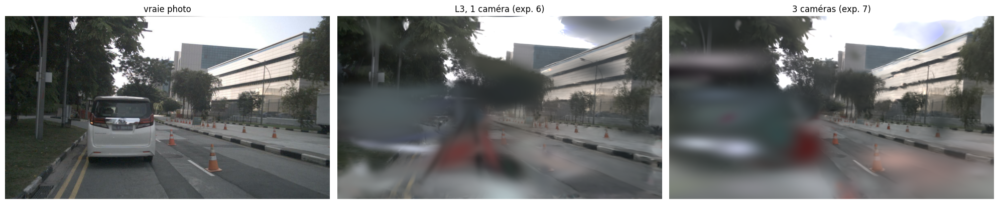

In [55]:
# Vraie photo | L3 1 caméra (exp. 6) | 3 caméras (exp. 7)
def render(pipeline, dataset, i):
    """Rendu de l'image i d'un groupe, en tableau numpy (H, W, 3)."""
    pipeline.eval()
    cam = dataset.cameras[i:i + 1].to(pipeline.model.device)
    with torch.no_grad():
        return pipeline.model.get_outputs_for_camera(cam)['rgb'].clamp(0, 1).cpu().numpy()

# 1) Première image CAM_FRONT de la val du modèle à 3 caméras
ds7 = pipe7.datamanager.eval_dataset
i7 = next(i for i in range(len(ds7)) if channel(sample_data[Path(ds7.image_filenames[i]).stem]) == 'CAM_FRONT')
token = Path(ds7.image_filenames[i7]).stem

# 2) La même image dans la val du modèle L3
run6 = Path(sorted(glob.glob('/kaggle/working/outputs/exp6_L3/splatfacto/*/'))[-1])
ckpt6 = glob.glob(str(run6 / 'nerfstudio_models/step-*.ckpt'))[0]          # le seul checkpoint gardé
_, pipe6, _, _ = eval_setup(run6 / 'config.yml', test_mode='val')
sd6 = torch.load(ckpt6, map_location='cpu')
pipe6.load_pipeline(sd6['pipeline'], sd6['step'])
ds6 = pipe6.datamanager.eval_dataset
i6 = next(i for i in range(len(ds6)) if Path(ds6.image_filenames[i]).stem == token)

# 3) Affichage
gt = np.asarray(Image.open(ds7.image_filenames[i7]).convert('RGB'))
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
for ax, img, title in zip(axes, [gt, render(pipe6, ds6, i6), render(pipe7, ds7, i7)],
                          ['vraie photo', 'L3, 1 caméra (exp. 6)', '3 caméras (exp. 7)']):
    ax.imshow(img); ax.set_title(title); ax.axis('off')
plt.tight_layout()
plt.savefig('/kaggle/working/exp7_front_compare.png', dpi=110)
plt.show()

A mon avis le model à 3 cam est nettement meilleur que celui à 1 sur l'image frontale. Ce qui est un bon signe. Ne pas oublier que la voiture est mobile donc non vu par les deux modèles à l'initialisation à priori. Il faut aussi noté que le ciel de exp_7 est nettement mieux dessiné que celui de L3.

## Expérience 7b : correction de l'exposition des caméras latérales

Pour chaque image latérale, je calcule un facteur de luminosité par rapport à la caméra avant. Je le mesure sur les points lidar fixes vus par les deux caméras au même moment, en lumière linéaire et non en couleurs d'écran. Quand une image a trop peu de points communs, je prends la médiane de sa caméra. Je divise ensuite l'image par son facteur et je réentraîne avec les mêmes réglages qu'exp7 : seules les images latérales changent.

In [56]:
# Variables utiles (si la session a redémarré)
import os, json, shutil, subprocess
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

os.chdir('/kaggle/working')
OUT3 = '/kaggle/working/nerf_data_3cams'
CAMS = ['CAM_FRONT_LEFT', 'CAM_FRONT', 'CAM_FRONT_RIGHT']
lidar_chain = scene_chain(0, 'LIDAR_TOP')
chains = {cam: scene_chain(0, cam) for cam in CAMS}
cam_times = {cam: np.array([s['timestamp'] for s in chain]) for cam, chain in chains.items()}


# Conversion couleurs d'écran (sRGB) <-> lumière linéaire
def to_linear(c):
    """sRGB 0-255 -> intensité lumineuse linéaire 0-1."""
    c = c / 255.0
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)

def to_srgb(l):
    """Intensité linéaire 0-1 -> sRGB 0-255."""
    l = np.clip(l, 0, 1)
    return 255.0 * np.where(l <= 0.0031308, 12.92 * l, 1.055 * l ** (1 / 2.4) - 0.055)


lidar_times = np.array([s['timestamp'] for s in lidar_chain])

def nearest(chain, times, t):
    """Élément de `chain` le plus proche de l'instant t."""
    return chain[int(np.argmin(np.abs(times - t)))]


def exposure_gain(sd_side, min_points=50):
    """Facteur de luminosité d'une image latérale par rapport à CAM_FRONT :
    même endroit réel, lumière linéaire moyenne dans l'image latérale / dans l'image avant.
    Renvoie None s'il y a trop peu de points vus par les deux caméras."""
    lid = nearest(lidar_chain, lidar_times, sd_side['timestamp'])               # balayage lidar le plus proche
    sd_front = nearest(chains['CAM_FRONT'], cam_times['CAM_FRONT'], sd_side['timestamp'])

    pw = lidar_to_world(lid)
    pw = pw[outside_boxes(pw, moving_boxes_at(lid['timestamp']))]               # décor fixe seulement

    cols = []
    for sd in (sd_side, sd_front):
        idx, u, v = project_to_camera(pw, sd)
        img = np.asarray(Image.open(os.path.join(DATAROOT, sd['filename'])).convert('RGB'), dtype=np.float32)
        col = np.full((len(pw), 3), np.nan)
        col[idx] = img[v, u]
        cols.append(col)

    both = ~np.isnan(cols[0][:, 0]) & ~np.isnan(cols[1][:, 0])                   # vus par les deux caméras
    if both.sum() < min_points:
        return None
    return to_linear(cols[0][both]).mean() / to_linear(cols[1][both]).mean()

CAM_FRONT_LEFT   médiane 5.07 | 0 images sans assez de points (-> médiane)
CAM_FRONT_RIGHT  médiane 0.76 | 0 images sans assez de points (-> médiane)


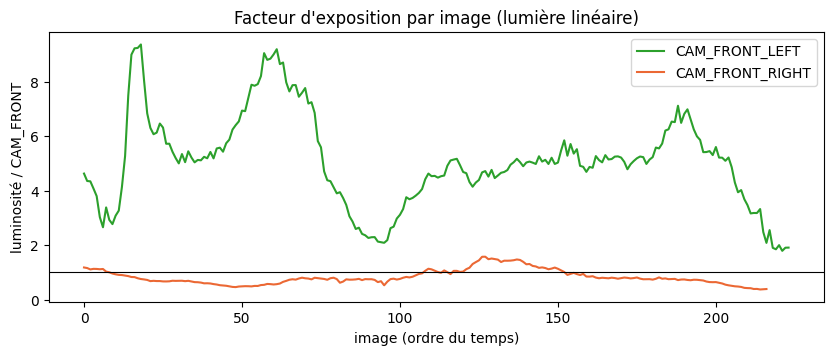

In [57]:
# Un facteur par image ; médiane de la caméra si pas assez de points communs
gains = {}
for cam in ['CAM_FRONT_LEFT', 'CAM_FRONT_RIGHT']:
    raw = [exposure_gain(s) for s in chains[cam]]
    median = np.median([g for g in raw if g is not None])
    gains[cam] = [g if g is not None else median for g in raw]
    n_missing = sum(g is None for g in raw)
    print(f'{cam:16s} médiane {median:.2f} | {n_missing} images sans assez de points (-> médiane)')

json.dump(gains, open('/kaggle/working/exp7b_gains.json', 'w'))     # garder les facteurs en fichier

# Les facteurs au fil du temps
plt.figure(figsize=(10, 3.5))
for cam, c in [('CAM_FRONT_LEFT', '#2ca02c'), ('CAM_FRONT_RIGHT', '#eb6834')]:
    plt.plot(gains[cam], c=c, label=cam)
plt.axhline(1, c='black', lw=0.8)
plt.xlabel('image (ordre du temps)'); plt.ylabel('luminosité / CAM_FRONT')
plt.legend(); plt.title("Facteur d'exposition par image (lumière linéaire)")
plt.show()

In [58]:
# nerf_data_3cams_expo : mêmes images, poses et découpage ; luminosité latérale corrigée
OUT3E = '/kaggle/working/nerf_data_3cams_expo'
os.makedirs(f'{OUT3E}/images', exist_ok=True)
shutil.copy(f'{OUT3}/transforms.json', f'{OUT3E}/transforms.json')
shutil.copy(f'{OUT3}/L3_3cams.ply', f'{OUT3E}/L3_3cams.ply')

for cam in CAMS:
    for i, s in enumerate(chains[cam]):
        src = os.path.join(DATAROOT, s['filename'])
        dst = f"{OUT3E}/images/{s['token']}.jpg"
        if cam == 'CAM_FRONT':
            shutil.copy(src, dst)                                   # référence : inchangée
            continue
        img = np.asarray(Image.open(src).convert('RGB'), dtype=np.float32)
        corrected = to_srgb(to_linear(img) / gains[cam][i])         # ramenée à la luminosité de l'avant
        Image.fromarray(corrected.round().astype(np.uint8)).save(dst, quality=95)

print(len(os.listdir(f'{OUT3E}/images')), 'images écrites')

665 images écrites


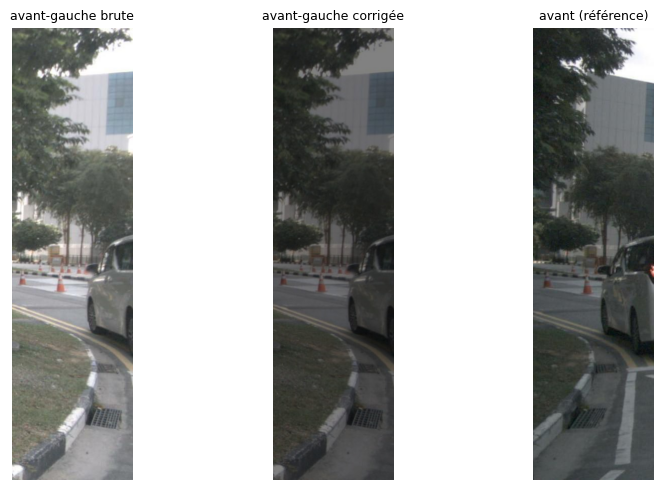

In [59]:
# Zone commune gauche, au même instant : avant-gauche brute | avant-gauche corrigée | avant
k = 19
sd_l = [s for s in chains['CAM_FRONT_LEFT'] if s['is_key_frame']][k]
sd_f = [s for s in chains['CAM_FRONT'] if s['is_key_frame']][k]
w = int(1600 * 0.15)
brute   = np.asarray(Image.open(os.path.join(DATAROOT, sd_l['filename'])))[:, -w:]
corrige = np.asarray(Image.open(f"{OUT3E}/images/{sd_l['token']}.jpg"))[:, -w:]
avant   = np.asarray(Image.open(os.path.join(DATAROOT, sd_f['filename'])))[:, :w]

fig, axes = plt.subplots(1, 3, figsize=(9, 5))
for ax, img, t in zip(axes, [brute, corrige, avant], ['avant-gauche brute', 'avant-gauche corrigée', 'avant (référence)']):
    ax.imshow(img); ax.set_title(t, fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

In [60]:
!df -h /kaggle/working

Filesystem      Size  Used Avail Use% Mounted on
/dev/loop2       20G   15G  5.2G  74% /kaggle/working


In [61]:
# # Mêmes réglages que exp7 ; seules les images latérales changent
# os.makedirs('/kaggle/working/logs', exist_ok=True)
# script = f"""
# start=$(date +%s)
# ns-train splatfacto \
#   --data {OUT3E} \
#   --experiment-name exp7b_expo \
#   --max-num-iterations 18000 \
#   --steps-per-save 2500 \
#   --save-only-latest-checkpoint False \
#   --pipeline.datamanager.cache-images-type uint8 \
#   --viewer.quit-on-train-completion True
# end=$(date +%s)
# echo $((end - start)) > /kaggle/working/logs/exp7b_seconds.txt
# """
# proc7b = subprocess.Popen(['bash', '-c', script], env=dict(os.environ, CUDA_VISIBLE_DEVICES='0'),
#                           stdout=open('/kaggle/working/logs/exp7b.log', 'w'), stderr=subprocess.STDOUT)

In [ ]:
# Pour chaque checkpoint d'exp7b : PSNR train, et val caméra par caméra
ckpts7b = sorted(glob.glob(str(run7b / 'nerfstudio_models/step-*.ckpt')))
dm7b = pipe7b.datamanager

curves7b = []
for ckpt in ckpts7b:
    sd = torch.load(ckpt, map_location='cpu')
    pipe7b.load_pipeline(sd['pipeline'], sd['step'])

    tr = per_image_metrics(pipe7b, dm7b.train_dataset, dm7b.cached_train)
    va = per_image_metrics(pipe7b, dm7b.eval_dataset, dm7b.cached_eval)

    row = {'step': sd['step'], 'n_gaussians': int(pipe7b.model.means.shape[0])}
    for m in ['psnr', 'ssim', 'lpips']:
        row[f'train_{m}'] = tr[m].mean()
        row[f'val_{m}'] = va[m].mean()
        for cam, v in va.groupby('camera')[m].mean().items():
            row[f'val_{m}_{cam}'] = v
    curves7b.append(row)
    print(sd['step'], f"val avant {row['val_psnr_CAM_FRONT']:.2f} dB")

json.dump(curves7b, open('/kaggle/working/exp7b_curves.json', 'w'), indent=2)

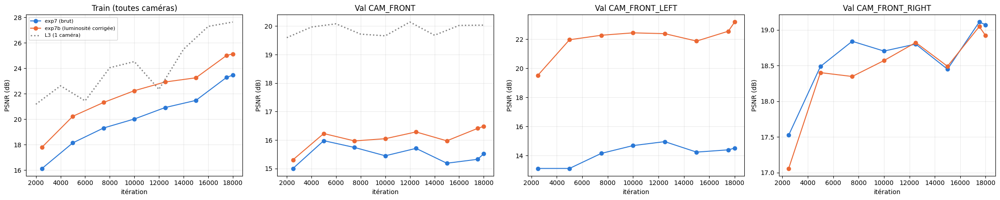

In [63]:
# PSNR : train | val avant | val gauche | val droite ; exp7 contre exp7b (et L3 en référence)
c7  = json.load(open('/kaggle/working/exp7_curves.json'))
c7b = json.load(open('/kaggle/working/exp7b_curves.json'))
L3  = json.load(open('/kaggle/working/exp6_curves.json'))['L3']

panels = [('train_psnr', 'Train (toutes caméras)'),
          ('val_psnr_CAM_FRONT', 'Val CAM_FRONT'),
          ('val_psnr_CAM_FRONT_LEFT', 'Val CAM_FRONT_LEFT'),
          ('val_psnr_CAM_FRONT_RIGHT', 'Val CAM_FRONT_RIGHT')]

fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, (key, title) in zip(axes, panels):
    ax.plot([r['step'] for r in c7],  [r[key] for r in c7],  '-o', c='#2a78d6', label='exp7 (brut)')
    ax.plot([r['step'] for r in c7b], [r[key] for r in c7b], '-o', c='#eb6834', label='exp7b (luminosité corrigée)')
    # Référence L3 (1 caméra) : seulement là où elle a un sens
    if key == 'train_psnr':
        ax.plot([r['step'] for r in L3], [r['train_psnr'] for r in L3], ':', c='gray', lw=2, label='L3 (1 caméra)')
    if key == 'val_psnr_CAM_FRONT':
        ax.plot([r['step'] for r in L3], [r['val_psnr'] for r in L3], ':', c='gray', lw=2, label='L3 (1 caméra)')
    ax.set_title(title); ax.set_xlabel('itération'); ax.set_ylabel('PSNR (dB)'); ax.grid(alpha=0.25)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig('/kaggle/working/exp7_vs_exp7b_psnr.png', dpi=120)
plt.show()

Ce que montrent les 3 graphiques :

Val CAM_FRONT (la comparaison propre) :

exp7b (orange) est au-dessus d’exp7 (bleu) à chaque itération, de 0,5 à 1 dB. Le gain est réel et constant, ce n’est pas du hasard.
Mais les deux restent plats autour de 16 dB, loin de L3 (20 dB). Il reste ≈ 3,5 dB inexpliqués.

Val CAM_FRONT_LEFT : exp7b fait un bond énorme (≈ 14 → 23 dB).

Une partie est mécanique (images de référence assombries). D’après un calcul approximatif, ce seul effet donnerait autour de +3 dB.
Le reste, environ +5 dB, serait un vrai progrès du modèle sur la zone de gauche. C’est une estimation grossière : à prendre avec prudence.

Val CAM_FRONT_RIGHT : les deux courbes sont quasi identiques. C’est logique : à droite, l’écart de luminosité était faible (rapport 1,16), donc la correction ne change presque rien.

Conclusion :

La correction de luminosité marche là où il y avait un conflit : beaucoup à gauche, un peu devant, rien à droite.
Mais la caméra avant reste bloquée vers 16 dB, contre 20 pour L3. La luminosité n’est pas la cause principale de ce problème

## Expérience 7c : le modèle à trois caméras a-t-il simplement besoin de plus de temps ?

### Pourquoi cette expérience
Sur les mêmes 40 images de validation de la caméra avant, mesurées avec le même code :

| Modèle | Caméras | PSNR de validation, caméra avant |
|---|---|---|
| L3 (exp. 6) | avant seule | 19,7 dB |
| exp7 | trois caméras avant | 15,5 dB |
| exp7b | trois caméras, luminosité corrigée | 16,5 dB |

Ajouter les caméras latérales fait baisser la qualité sur la caméra avant. J'ai déjà écarté plusieurs pistes :
- un bug d'export : les trois caméras sont bien apprises en entraînement (22 à 25 dB) ;
- un problème de calibration : aucun objet dédoublé n'est visible ;
- le découpage : exp7 avait même 11 images avant de plus en entraînement que L3, il était donc favorisé ;
- la luminosité différente entre caméras : elle est réelle (l'avant-gauche voit le même décor environ 2,2 fois plus clair), mais sa correction (exp7b) n'a regagné qu'environ 1 dB sur 4,2.

L'hypothèse testée ici est le temps d'assimilation. Avec trois caméras, il y a environ trois fois plus d'images d'entraînement pour le même nombre d'itérations (une image par itération) et le même programme d'entraînement. Chaque image est donc vue environ trois fois moins souvent : 45 passages contre 144 pour L3. Or le programme de splatfacto est compté en itérations. L'ajout de gaussiennes s'arrête à 15 000, le pas d'apprentissage décroît au fil des itérations, et chaque décision d'ajout (toutes les 100 itérations) ne voit la zone avant qu'environ 33 fois au lieu de 100. exp7 avait donc le même calendrier pour trois fois plus de travail.

### Données
Les images sont celles d'exp7b, avec la luminosité des caméras latérales ramenée à celle de la caméra avant. Le nuage lidar est le même : L3 à trois caméras (objets mobiles retirés, sweeps inclus, points vus par au moins une des trois caméras).

### Découpage train / val / test
Chaque caméra a 39 keyframes (2 par seconde) et des sweeps entre elles, soit environ 12 images par seconde au total.

Pour L3 (caméra avant seule, 224 images), une keyframe sur cinq va en test (les n° 2, 7, 12, etc.) et une autre en validation (les n° 4, 9, 14, etc.). Les sweeps à moins de 0,25 s d'une keyframe de test ou de validation suivent son groupe, et toutes les autres images vont en entraînement. Le but est de mettre des blocs de temps entiers en validation et en test, pour que le modèle n'ait jamais vu d'image quasi identique à une image d'évaluation.

Pour exp7c (trois caméras, 665 images), le groupe de chaque image avant est recopié du fichier de L3 : la caméra avant est donc découpée exactement comme dans L3, ce que j'ai vérifié. Chaque image des caméras gauche et droite prend le groupe de la photo avant la plus proche dans le temps, si bien que les trois caméras ont les mêmes instants dans chaque groupe.

| Caméra | train | val | test | total |
|---|---|---|---|---|
| CAM_FRONT | 125 | 47 | 52 | 224 |
| CAM_FRONT_LEFT | 123 | 48 | 53 | 224 |
| CAM_FRONT_RIGHT | 122 | 46 | 49 | 217 |
| total | 370 | 141 | 154 | 665 |

### Entraînement
J'entraîne 55 000 itérations : pour 370 images, ça fait environ 148 passages par image, comme L3 (environ 144). J'étire aussi tout le programme d'entraînement par trois, pour que chaque image avant reçoive le même traitement que dans L3. exp7c vers 54 000 itérations correspond ainsi à L3 à 18 000.

| Réglage | Rôle | L3 | exp7c |
|---|---|---|---|
| `warmup-length` | attente avant le premier ajout de gaussiennes | 500 | 1 500 |
| `refine-every` | fréquence des décisions d'ajout et de suppression | 100 | 300 |
| `reset-alpha-every` | reset d'opacité toutes les N décisions | 30 (soit toutes les 3 000 it.) | 30 (soit toutes les 9 000 it.) |
| `stop-split-at` | fin de l'ajout de gaussiennes | 15 000 | 45 000 |
| `stop-screen-size-at` | fin du nettoyage des grosses gaussiennes à l'écran | 4 000 | 12 000 |
| `resolution-schedule` | montée progressive en résolution | 3 000 | 9 000 |
| `sh-degree-interval` | montée progressive du détail des couleurs | 1 000 | 3 000 |
| `means.scheduler.max-steps` | vitesse de décroissance du pas d'apprentissage | 30 000 | 90 000 |

Le reset d'opacité est un ménage périodique : splatfacto plafonne l'opacité de toutes les gaussiennes, puis supprime celles qui ne la regagnent pas (gaussiennes inutiles, ou « floaters »). Juste après, le modèle est temporairement moins bon. Ici, il a lieu toutes les 9000 itérations, jusqu'à 45 000.

Je sauvegarde toutes les 10 000 itérations (10k, 20k, 30k, 40k, 50k, puis 55k) et non toutes les 9000. Une sauvegarde toutes les 9000 itérations tomberait pile sur chaque reset et sous-estimerait le modèle, comme dans l'expérience 5.

Les évaluations automatiques de nerfstudio sont désactivées pendant l'entraînement, ce qui ne change rien à l'apprentissage. Je fais mes propres mesures ensuite, checkpoint par checkpoint.

### Ce que je mesure
Le PSNR en fonction du nombre d'itérations, puis la SSIM et le LPIPS :
- pour L3 : entraînement et validation, caméra avant ;
- pour exp7c : entraînement sur la caméra avant et sur les trois caméras ;
- pour exp7c : validation sur la caméra avant, la gauche, la droite, et la moyenne des trois.

Un second graphique reprend les mêmes courbes avec en abscisse le nombre de passages par image, pour comparer L3 et exp7c à traitement égal.

### Lecture attendue
- Si la validation avant d'exp7c remonte vers 20 dB, le problème était le temps d'assimilation.
- Si elle reste vers 16 dB, la cause est ailleurs (par exemple les objets mobiles ou la zone de gauche), et il faudra la chercher.

In [64]:
# Ce dont exp7c a besoin : est-ce encore là ?
import os
for p in ['/kaggle/working/nerf_data_tvt/transforms.json',          # découpage de L3
          '/kaggle/working/nerf_data_3cams_expo/images',             # images à luminosité corrigée
          '/kaggle/working/nerf_data_3cams_expo/L3_3cams.ply',       # nuage lidar 3 caméras
          '/kaggle/working/exp6_curves.json',                        # courbes de L3
          '/kaggle/working/exp7b_curves.json']:                      # courbes d'exp7b
    ok = os.path.exists(p)
    extra = f"({len(os.listdir(p))} fichiers)" if ok and os.path.isdir(p) else ''
    print('OK ' if ok else 'MANQUE', p, extra)

# Contenu du nouveau dataset
!ls -R /kaggle/input/datasets/adbiashouessou/syntha-drive-experiences | head -40

OK  /kaggle/working/nerf_data_tvt/transforms.json 
OK  /kaggle/working/nerf_data_3cams_expo/images (665 fichiers)
OK  /kaggle/working/nerf_data_3cams_expo/L3_3cams.ply 
OK  /kaggle/working/exp6_curves.json 
OK  /kaggle/working/exp7b_curves.json 
/kaggle/input/datasets/adbiashouessou/syntha-drive-experiences:
eval_nerf_data_A_prime.json
eval_nerf_data_B_30k.json
eval_nerf_data_B.json
exp5_curves.json
exp5_curves.png
exp6_curves.json
exp6_curves.png
exp6_L3_left.csv
exp6_L3_left.png
exp7_curves.json
exp7_curves.png


In [65]:
# Données exp7c : images corrigées d'exp7b, nouveau découpage
import os, json, shutil
import numpy as np
import pandas as pd
from pathlib import Path

OUT3E = '/kaggle/working/nerf_data_3cams_expo'     # images à luminosité corrigée
OUT7C = '/kaggle/working/nerf_data_exp7c'
os.makedirs(OUT7C, exist_ok=True)

# 1) Découpage de L3 (caméra avant) : {identifiant: groupe}
tvt = json.load(open('/kaggle/working/nerf_data_tvt/transforms.json'))
group_L3 = {Path(f).stem: g for g in ['train', 'val', 'test'] for f in tvt[f'{g}_filenames']}

# 2) Instants des photos avant, avec leur groupe L3 (triés dans le temps)
front = sorted((sample_data[t]['timestamp'], g) for t, g in group_L3.items())
front_times = np.array([ts for ts, _ in front])
front_groups = [g for _, g in front]

def group_of(token):
    """Avant : groupe de L3. Gauche / droite : groupe de la photo avant la plus proche dans le temps."""
    if channel(sample_data[token]) == 'CAM_FRONT':
        return group_L3[token]
    i = int(np.argmin(np.abs(front_times - sample_data[token]['timestamp'])))
    return front_groups[i]

# 3) Nouveau transforms.json : mêmes images, poses et nuage qu'exp7b ; seul le découpage change
tj = json.load(open(f'{OUT3E}/transforms.json'))
split = {'train': [], 'val': [], 'test': []}
for fr in tj['frames']:
    split[group_of(Path(fr['file_path']).stem)].append(fr['file_path'])
for g in split:
    tj[f'{g}_filenames'] = split[g]
json.dump(tj, open(f'{OUT7C}/transforms.json', 'w'), indent=2)

# Images et nuage : raccourci et copie (pas de copie des 665 images)
if not os.path.exists(f'{OUT7C}/images'):
    os.symlink(f'{OUT3E}/images', f'{OUT7C}/images')
shutil.copy(f'{OUT3E}/L3_3cams.ply', f'{OUT7C}/L3_3cams.ply')

# 4) Vérifications
rows = [(channel(sample_data[Path(f).stem]), g) for g in split for f in split[g]]
display(pd.crosstab(pd.Series([r[0] for r in rows], name='caméra'),
                    pd.Series([r[1] for r in rows], name='groupe'), margins=True, margins_name='total'))

same = all(group_of(t) == g for t, g in group_L3.items())
print('Caméra avant identique à L3 :', same)

groupe,test,train,val,total
caméra,,,,
CAM_FRONT,52,125,47,224
CAM_FRONT_LEFT,53,123,48,224
CAM_FRONT_RIGHT,49,122,46,217
total,154,370,141,665


Caméra avant identique à L3 : True


In [66]:
!ns-train splatfacto --help 2>/dev/null | grep -E -o -- "--[a-z.-]*(refine-every|reset-alpha-every|stop-split-at|warmup-length|stop-screen-size-at|sh-degree-interval|resolution-schedule|means\.scheduler\.max-steps)[a-z.-]*" | sort -u

--optimizers.means.scheduler.max-steps
--pipeline.model.refine-every
--pipeline.model.reset-alpha-every
--pipeline.model.resolution-schedule
--pipeline.model.sh-degree-interval
--pipeline.model.stop-screen-size-at
--pipeline.model.stop-split-at
--pipeline.model.warmup-length


In [67]:
!df -h /kaggle/working

Filesystem      Size  Used Avail Use% Mounted on
/dev/loop2       20G   15G  5.2G  74% /kaggle/working


In [68]:
# exp7c : 3 caméras, découpage avant = L3, 55 000 itérations, programme étiré ×3
import os, subprocess
os.makedirs('/kaggle/working/logs', exist_ok=True)

script = """
start=$(date +%s)
ns-train splatfacto \
  --data /kaggle/working/nerf_data_exp7c \
  --experiment-name exp7c_long \
  --max-num-iterations 55000 \
  --steps-per-save 10000 \
  --save-only-latest-checkpoint False \
  --steps-per-eval-image 1000000 \
  --steps-per-eval-all-images 1000000 \
  --pipeline.datamanager.cache-images-type uint8 \
  --pipeline.model.warmup-length 1500 \
  --pipeline.model.refine-every 300 \
  --pipeline.model.reset-alpha-every 30 \
  --pipeline.model.stop-split-at 45000 \
  --pipeline.model.stop-screen-size-at 12000 \
  --pipeline.model.resolution-schedule 9000 \
  --pipeline.model.sh-degree-interval 3000 \
  --optimizers.means.scheduler.max-steps 90000 \
  --viewer.quit-on-train-completion True
end=$(date +%s)
echo $((end - start)) > /kaggle/working/logs/exp7c_seconds.txt
"""
proc7c = subprocess.Popen(['bash', '-c', script], env=dict(os.environ, CUDA_VISIBLE_DEVICES='0'),
                          stdout=open('/kaggle/working/logs/exp7c.log', 'w'), stderr=subprocess.STDOUT)

In [69]:
# # Run exp7c et ses sauvegardes
# import os, glob, json, torch
# import numpy as np, pandas as pd
# import matplotlib.pyplot as plt
# from pathlib import Path

# os.chdir('/kaggle/working')
# os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'
# from nerfstudio.utils.eval_utils import eval_setup

# run7c = Path(sorted(glob.glob('/kaggle/working/outputs/exp7c_long/splatfacto/*/'))[-1])
# ckpts7c = sorted(glob.glob(str(run7c / 'nerfstudio_models/step-*.ckpt')))
# print(run7c.name, '|', [Path(c).stem for c in ckpts7c])
# print('durée :', int(open('/kaggle/working/logs/exp7c_seconds.txt').read()) // 60, 'min')

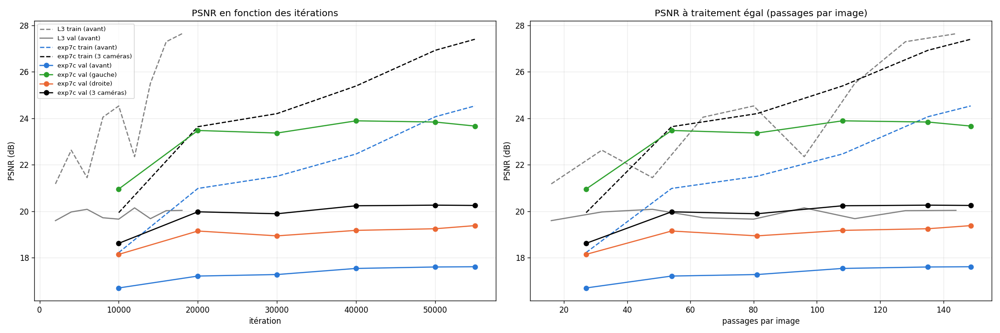

In [72]:
from IPython.display import Image as ShowImage, display
display(ShowImage('/kaggle/working/exp7c_psnr.png'))

In [76]:
# Remplacer le raccourci abîmé par une vraie copie des images corrigées
import os, shutil
p = '/kaggle/working/nerf_data_exp7c/images'
if os.path.islink(p) or os.path.isfile(p):
    os.remove(p)                                                     # supprime le raccourci abîmé
if not os.path.isdir(p):
    shutil.copytree('/kaggle/working/nerf_data_3cams_expo/images', p)
print(len(os.listdir(p)), 'images')

665 images


## Décalages latéraux : L3 contre exp7c

Je charge L3 et exp7c avec leurs images de test, puis je décale la caméra de −3 à +3 m sur le côté, sur trois keyframes de test (début, milieu et fin de la scène), pour voir jusqu'où chaque modèle reste crédible.

In [82]:
# L3 et exp7c, chargés avec leur groupe de test
import copy, glob, json, os, torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

os.chdir('/kaggle/working')

def load_model(run, ckpt):
    """Charge un run nerfstudio avec ses images de test, et les gaussiennes du checkpoint donné."""
    _, pipe, _, _ = eval_setup(run / 'config.yml', test_mode='test')
    sd = torch.load(ckpt, map_location='cpu')
    pipe.load_pipeline(sd['pipeline'], sd['step'])
    pipe.eval()
    scale = json.load(open(run / 'dataparser_transforms.json'))['scale']   # mètres vers unités du modèle
    return pipe, scale

run_L3 = Path(sorted(glob.glob('/kaggle/working/outputs/exp6_L3/splatfacto/*/'))[-1])
ckpt_L3 = sorted(glob.glob(str(run_L3 / 'nerfstudio_models/step-*.ckpt')))[-1]
run_7c = Path(sorted(glob.glob('/kaggle/working/outputs/exp7c_long/splatfacto/*/'))[-1])
ckpt_7c = str(run_7c / 'nerfstudio_models/step-000054999.ckpt')

models = {'L3 (1 caméra)': load_model(run_L3, ckpt_L3),
          'exp7c (3 caméras)': load_model(run_7c, ckpt_7c)}
for name, (pipe, scale) in models.items():
    print(f'{name:18s} échelle {scale:.4f} | {len(pipe.datamanager.eval_dataset)} images de test')

[22:19:19] Auto image downscale factor of 1                                                 ]8;id=817357;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py\nerfstudio_dataparser.py]8;;\:]8;id=643566;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py#484\484]8;;\

            Dataset is overriding train_indices to [1, 2, 3, 4, 5, 7, 8, 10, 14, 16, 17,    ]8;id=962757;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py\nerfstudio_dataparser.py]8;;\:]8;id=315767;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py#203\203]8;;\
           18, 19, 20, 21, 22, 24, 26, 27, 29, 31, 36, 38, 40, 41, 42, 43, 46, 47, 48, 52,                              
           55, 57, 58, 61, 63, 64, 67, 68, 69, 72, 75, 77, 79, 80, 84, 87, 88, 89, 90, 93,                              
           94, 95, 96, 97, 100, 102, 104, 106, 107, 109, 110, 111, 114, 115, 116, 117, 118,                             
           119, 120, 121, 122, 124, 126, 129, 130, 132, 138, 140, 141, 143, 144, 145, 146,                              
           148, 149, 153, 155, 157, 158, 159, 160, 162, 163, 164, 168, 170, 171, 176, 177,                              
           178, 179, 181, 183, 186, 187, 189, 190, 192, 193, 194, 196, 200, 205, 206, 207,                              
           210, 211, 214, 216, 217, 218, 219, 220, 223]                                                                 

            Dataset is overriding test_indices to [0, 6, 12, 13, 15, 25, 30, 34, 45, 49,    ]8;id=888187;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py\nerfstudio_dataparser.py]8;;\:]8;id=88115;file:///usr/local/lib/python3.12/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py#203\203]8;;\
           51, 54, 60, 65, 66, 70, 71, 74, 82, 85, 92, 98, 99, 101, 108, 112, 123, 125,                                 
           128, 131, 134, 139, 147, 150, 151, 154, 156, 165, 166, 169, 173, 180, 184, 185,                              
           191, 198, 202, 204, 213, 215, 221, 222]                                                                      

/usr/local/lib/python3.12/dist-packages/torchmetrics/functional/image/lpips.py:332: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  self.load_state_dict(torch.load(model_path, map_location="cpu"), strict=False)


Loading latest checkpoint from load_dir

/usr/local/lib/python3.12/dist-packages/nerfstudio/utils/eval_utils.py:62: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  loaded_state = torch.load(load_path, map_location="cpu")


... (7 outputs left out)

/usr/local/lib/python3.12/dist-packages/nerfstudio/utils/eval_utils.py:62: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  loaded_state = torch.load(load_path, map_location="cpu")


✅ Done loading checkpoint from outputs/exp7c_long/splatfacto/2026-10-30_121126/nerfstudio_models/step-000054999.ckpt

/tmp/ipykernel_58/743583292.py:13: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  sd = torch.load(ckpt, map_location='cpu')


L3 (1 caméra)      échelle 0.0194 | 52 images de test
exp7c (3 caméras)  échelle 0.0193 | 154 images de test


In [83]:
# Décaler une caméra de d mètres sur le côté, puis faire le rendu
def render_shifted(pipe, scale, dataset, i, d_m):
    cam = copy.deepcopy(dataset.cameras[i:i + 1])
    c2w = cam.camera_to_worlds                     # (1, 3, 4) : colonnes = axes de la caméra, puis position
    right = c2w[0, :, 0]                            # 1re colonne = direction « droite » de la caméra
    c2w[0, :, 3] += right * d_m * scale             # déplacement de d mètres, converti à l'échelle du modèle
    with torch.no_grad():
        out = pipe.model.get_outputs_for_camera(cam.to(pipe.model.device))
    return out['rgb'].clamp(0, 1).cpu().numpy()

# Keyframes CAM_FRONT de test, présentes dans le test des deux modèles
def index_by_token(dataset):
    return {Path(f).stem: i for i, f in enumerate(dataset.image_filenames)}

idx = {name: index_by_token(pipe.datamanager.eval_dataset) for name, (pipe, _) in models.items()}
common = set.intersection(*[set(d) for d in idx.values()])
keys = sorted([tok for tok in common
               if sample_data[tok]['is_key_frame'] and channel(sample_data[tok]) == 'CAM_FRONT'],
              key=lambda tok: sample_data[tok]['timestamp'])
chosen = [keys[0], keys[len(keys) // 2], keys[-1]]      # début, milieu, fin de la scène
print(len(keys), 'keyframes de test avant en commun ; choisies :', chosen)

8 keyframes de test avant en commun ; choisies : ['d0d9ef23e3934ea09d55afdc24db9827', 'addcad764798404b8141c9d40b413e73', '6c8111f474b943f589b4da1e3444c1c0']


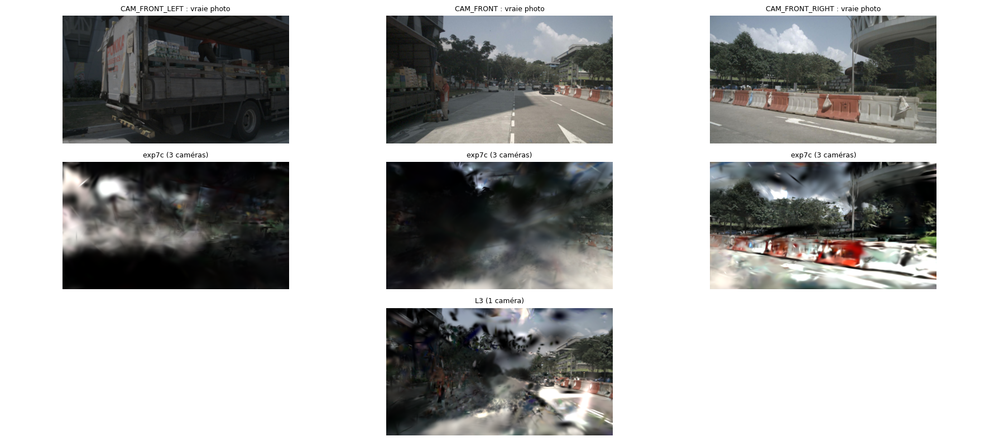

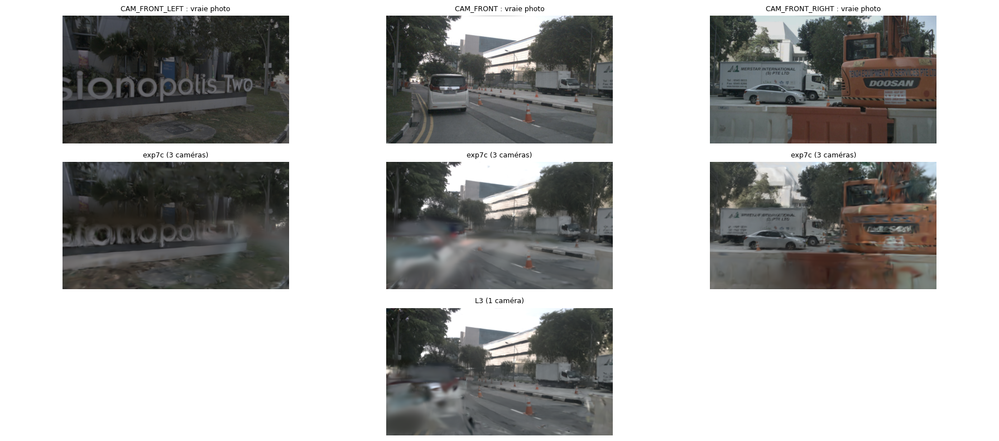

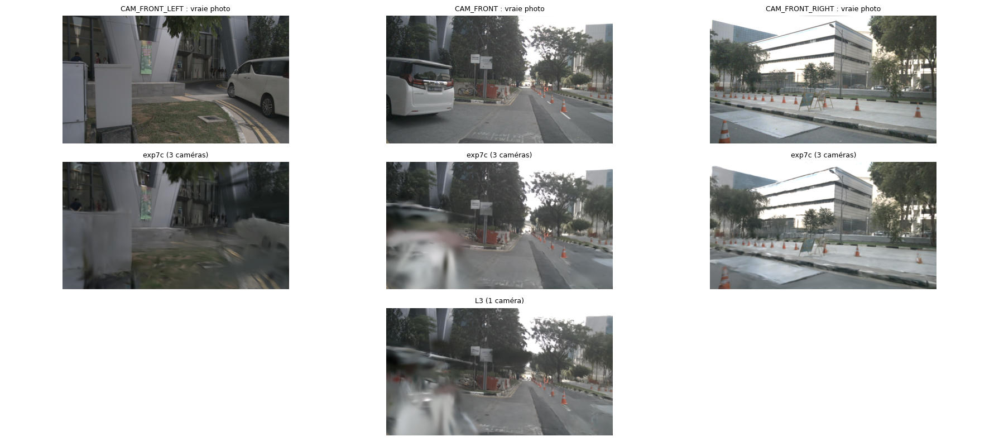

In [85]:
# Même instant (une keyframe de test) : vraie photo et rendus, pour les 3 caméras
CAMS = ['CAM_FRONT_LEFT', 'CAM_FRONT', 'CAM_FRONT_RIGHT']

def same_instant(token_front, cam):
    """Keyframe de la caméra `cam` prise au même instant (même sample) que la keyframe avant."""
    st = sample_data[token_front]['sample_token']
    return next(s['token'] for s in sample_data.values()
                if s['sample_token'] == st and s['is_key_frame'] and channel(s) == cam)

pipe7c, scale7c = models['exp7c (3 caméras)']
pipeL3, scaleL3 = models['L3 (1 caméra)']
ds7c, dsL3 = pipe7c.datamanager.eval_dataset, pipeL3.datamanager.eval_dataset

for tok_front in chosen:                                   # début, milieu, fin de la scène
    fig, axes = plt.subplots(3, 3, figsize=(18, 8))
    for col, cam in enumerate(CAMS):
        tok = same_instant(tok_front, cam)
        i7 = idx['exp7c (3 caméras)'][tok]
        # Vraie photo telle que le modèle l'a vue (corrigée en luminosité pour gauche et droite)
        axes[0, col].imshow(np.asarray(Image.open(ds7c.image_filenames[i7])))
        axes[0, col].set_title(f'{cam} : vraie photo', fontsize=9)
        axes[1, col].imshow(render_shifted(pipe7c, scale7c, ds7c, i7, 0))
        axes[1, col].set_title('exp7c (3 caméras)', fontsize=9)
        if cam == 'CAM_FRONT':                             # L3 ne connaît que la caméra avant
            axes[2, col].imshow(render_shifted(pipeL3, scaleL3, dsL3, idx['L3 (1 caméra)'][tok], 0))
            axes[2, col].set_title('L3 (1 caméra)', fontsize=9)
    for ax in axes.ravel():
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(f'/kaggle/working/scene3cams_{tok_front[:8]}.png', dpi=100)
    plt.show()

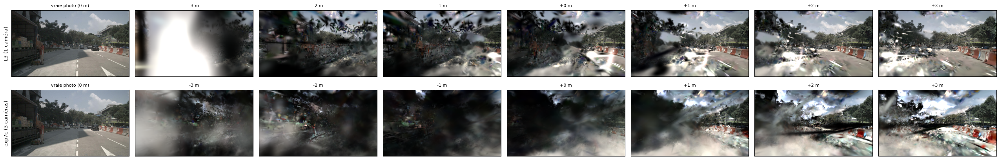

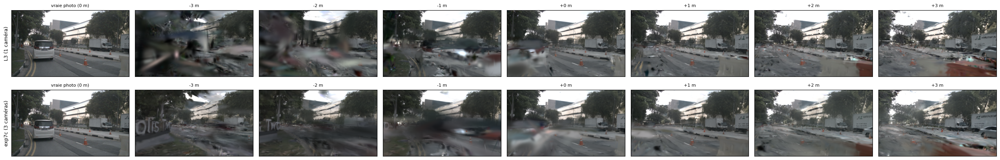

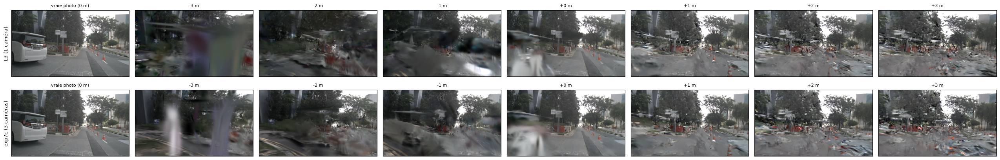

In [84]:
# Lignes : modèles ; colonnes : décalages ; plus la vraie photo à 0 m
shifts = [-3, -2, -1, 0, 1, 2, 3]

for tok in chosen:
    fig, axes = plt.subplots(len(models), len(shifts) + 1, figsize=(3.2 * (len(shifts) + 1), 2.2 * len(models)))
    photo = np.asarray(Image.open(os.path.join(DATAROOT, sample_data[tok]['filename'])))
    for row, (name, (pipe, scale)) in enumerate(models.items()):
        ds = pipe.datamanager.eval_dataset
        axes[row, 0].imshow(photo)
        axes[row, 0].set_title('vraie photo (0 m)', fontsize=8)
        axes[row, 0].set_ylabel(name, fontsize=9)
        for col, d in enumerate(shifts, start=1):
            axes[row, col].imshow(render_shifted(pipe, scale, ds, idx[name][tok], d))
            axes[row, col].set_title(f'{d:+d} m', fontsize=8)
    for ax in axes.ravel():
        ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout()
    plt.savefig(f'/kaggle/working/shift_{tok[:8]}.png', dpi=100)
    plt.show()

# Bilan de la phase splatfacto et passage à drivestudio / OmniRe

## 1. Ce qui a été fait avec splatfacto (nerfstudio)
Scène nuScenes `scene-0061` (Singapour, ≈ 20 s), reconstruction par 3D Gaussian Splatting de base (splatfacto) :

| Exp. | Question | Résultat principal |
|---|---|---|
| 1–3 | Reconstruire la scène avec la caméra avant ; apport des sweeps | Les sweeps (≈ 12 images/s au lieu de 2) améliorent la reconstruction |
| 4–5 | Initialisation lidar ; nombre d'itérations | Le lidar améliore surtout le LPIPS ; la val plafonne vers 18 000 itérations |
| 6 | Quel nuage lidar (brut / sans objets mobiles / avec sweeps) ? | Meilleur départ avec le nuage nettoyé et dense (L3), mais résultat final identique (≈ 20 dB en val) |
| 7, 7b, 7c | Apprendre avec les 3 caméras avant | Les côtés sont appris, mais la vue avant perd ≈ 2,4 dB, même avec la luminosité corrigée et 3× plus d'entraînement |
| Décalages | Déplacer la caméra de −3 à +3 m | Avec 3 caméras, la scène tient mieux vers la gauche ; au-delà de ≈ 2 m, tout se dégrade |

## 2. Difficultés observées
1. **Floaters** : des gaussiennes placées près de la caméra reproduisent les images d'entraînement mais masquent la scène depuis toute autre position. Fort surapprentissage (exp. 6 : ≈ 27,6 dB en train contre ≈ 20 dB en val).
2. **Objets mobiles** : la voiture qui roule devant nous devient une grosse tache floue au centre de l'image ; c'est la plus grande source d'erreur sur la vue avant.
3. **Conflit entre caméras** : chaque caméra règle son exposition seule (l'avant-gauche voit le même décor ≈ 2,2× plus clair que l'avant). Une correction globale par image n'a regagné que ≈ 1 dB. Avec 3 caméras, la vue avant est moins bien apprise même sur ses images d'entraînement (≈ 24,5 contre ≈ 27,6 dB à traitement égal).
4. **Extrapolation** : dès qu'on s'écarte de la trajectoire (≈ 2 m et plus), le modèle ne sait plus rien : zones jamais vues, géométrie mal contrainte.
5. **Le lidar ne sert qu'au départ** : il place les gaussiennes initiales, puis plus rien ne les maintient à la bonne distance.

## 3. Pourquoi le 3DGS de base échoue en conduite
Le 3DGS (Kerbl et al., SIGGRAPH 2023, Inria) suppose :
- **une scène immobile** → faux en conduite (voitures, piétons) ;
- **beaucoup d'angles de vue autour de chaque point** → faux : la voiture avance tout droit, chaque point est vu presque toujours du même côté, et les distances sont mal déterminées (d'où les floaters) ;
- **une seule caméra, ou des caméras aux réglages identiques** → faux : 3 à 6 caméras avec chacune leur exposition ;
- **pas de ciel à l'infini** → le ciel est collé n'importe où, souvent près de la caméra.

Ces échecs ne viennent pas des réglages : ils viennent du **modèle lui-même**, qui n'a pas de quoi représenter le mouvement, les distances ou les différences entre caméras.

## 4. Ce qu'apportent les méthodes spécialisées
**OmniRe** (Chen et al., ICLR 2025) représente la scène comme un **graphe de scène en gaussiennes** : chaque élément a ses gaussiennes et sa façon de bouger.

| Difficulté observée | Réponse d'OmniRe |
|---|---|
| Objets mobiles (voitures) | une maquette par véhicule, fixée dans le repère de sa boîte 3D et déplacée avec elle |
| Piétons, cyclistes | gaussiennes accrochées à un modèle de corps humain (SMPL), animé par les poses estimées |
| Floaters, distances fausses | le lidar contrôle la profondeur **pendant tout l'entraînement** |
| Ciel | modèle de ciel séparé, à l'infini |
| Couleurs différentes entre caméras | correction de couleur apprise par caméra |
| Éditer la scène (cas limites) | chaque acteur est un nœud séparé : on peut le déplacer, le supprimer, en ajouter |

**drivestudio** est la boîte à outils publique des auteurs d'OmniRe : l'équivalent de nerfstudio, mais spécialisé conduite. Elle lit directement nuScenes (6 caméras, lidar, boîtes) et contient plusieurs méthodes (OmniRe, et des versions d'autres méthodes comme Street Gaussians), ce qui permet de les comparer sur les mêmes données.

Autres méthodes de la même famille, pour situer :
- **Street Gaussians** (Yan et al., ECCV 2024) : véhicules rigides séparés, pas de piétons déformables ;
- **DrivingGaussian** (Zhou et al., CVPR 2024) : caméras tout autour, décor + objets dynamiques ;
- **HUGS** (Zhou et al., CVPR 2024) : ajoute la sémantique et le mouvement des véhicules ;
- **PVG** (Chen et al., arXiv 2023) : mouvement sans boîtes, mais objets non séparés (pas d'édition) ;
- **NeuRAD** (Tonderski et al., CVPR 2024) : basée sur NeRF, simule aussi le lidar.

## 5. Ce que la phase splatfacto apporte quand même
- Une **référence chiffrée** : les problèmes du 3DGS de base sont mesurés, pas supposés.
- Une **méthode d'évaluation propre** : découpage par blocs de temps, choix sur la val, mêmes images pour comparer, contrôles avant entraînement.
- Des **leçons pratiques** : resets d'opacité et choix des points de mesure, luminosité entre caméras, coût réel des sweeps et du lidar.

## Références
- Kerbl et al., *3D Gaussian Splatting for Real-Time Radiance Field Rendering*, SIGGRAPH 2023.
- Chen et al., *OmniRe: Omni Urban Scene Reconstruction*, ICLR 2025.
- Yan et al., *Street Gaussians: Modeling Dynamic Urban Scenes with Gaussian Splatting*, ECCV 2024.
- Zhou et al., *DrivingGaussian: Composite Gaussian Splatting for Surrounding Dynamic Autonomous Driving Scenes*, CVPR 2024.
- Zhou et al., *HUGS: Holistic Urban 3D Scene Understanding via Gaussian Splatting*, CVPR 2024.
- Chen et al., *Periodic Vibration Gaussian: Dynamic Urban Scene Reconstruction and Real-time Rendering*, arXiv 2023.
- Tonderski et al., *NeuRAD: Neural Rendering for Autonomous Driving*, CVPR 2024.